# Apprentissage automatique et survie des partis autoritaires (ARPD)
*Fedi Jouili*

**Objectif :** compléter les modèles de Cox de `final_panel.ipynb` par un **benchmark prédictif**. L'apprentissage automatique ne remplace pas les modèles de Cox, qui restent l'outil d'inférence (hazard ratios, intervalles de confiance, tests). Il répond à trois questions :
1. **Prédiction** : un modèle flexible prédit-il mieux la durée de vie des partis que le modèle de Cox, sur des partis qu'il n'a jamais vus ?
2. **Spécification** : existe-t-il des effets non linéaires ou des interactions que le modèle de Cox ne capture pas ?
3. **Cohérence** : les variables jugées importantes par l'apprentissage automatique sont-elles celles que le modèle de Cox identifie (origine, niveau démocratique, clientélisme, conflit) ?

## Plan du notebook
0. Configuration & imports
1. Chargement et contrôles des données
2. Protocole d'évaluation (validation croisée groupée par pays)
3. Tâche A : survie par spell
4. Tâche B : hasard en temps discret
5. Comparaison
6. Interprétation
7. Limites et conclusion
8. Export des résultats pour le site

## 0. Configuration & imports

In [1]:
# ============================================================
# Configuration et imports
# ============================================================
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedGroupKFold
from sksurv.util import Surv

RANDOM_STATE = 42
ALPHA = 0.05
N_FOLDS = 5
N_REPEATS = 10

# Racine du projet : fonctionne que le notebook soit lancé depuis la racine ou depuis notebooks/
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
assert (PROJECT_ROOT / "data").is_dir(), f"Racine du projet introuvable depuis {Path.cwd()}"
DATA_DIR = PROJECT_ROOT / "data" / "processed"


## 1. Chargement et contrôles des données

Les deux jeux de données sont exportés par `final_panel.ipynb` (Section 7.3) : ce sont exactement ceux des modèles de Cox.
* **Jeu statique** (Tâche A) : une ligne par spell, covariables mesurées à l'entrée au pouvoir.
* **Jeu time-varying** (Tâche B) : une ligne par parti-année, covariables macro retardées d'un an.

Avant toute modélisation, nous vérifions que les fichiers correspondent aux métadonnées de l'export et qu'aucune variable ne fait **fuiter** l'issue : aucune information connue seulement à la fin du spell (mode de sortie du pouvoir, dernière année, indicateur de censure, moyennes ou maxima calculés sur toute la durée du spell) ne doit servir de covariable.

In [2]:
# ============================================================
# 1.1 Chargement des données exportées par final_panel.ipynb
# ============================================================
with open(DATA_DIR / "ml_metadata.json", encoding="utf-8") as f:
    meta = json.load(f)

static = pd.read_csv(DATA_DIR / meta["static"]["file"])
tv = pd.read_csv(DATA_DIR / meta["timevarying"]["file"])
STATIC_FEATURES = meta["static"]["features"]
TV_FEATURES = meta["timevarying"]["features"]

print(f"Export du {meta['created']} ({meta['source_notebook']})")
print(f"Jeu statique       : {static.shape}")
print(f"Jeu time-varying   : {tv.shape}")


Export du 2026-10-18 (notebooks/final_panel.ipynb)
Jeu statique       : (224, 16)
Jeu time-varying   : (3653, 20)


In [3]:
# ============================================================
# 1.2 Contrôles d'intégrité et de fuite d'information
# ============================================================
STATIC_KEYS = ["spell_id", "Country", "duration", "event"]
TV_KEYS = ["row_id", "spell_id", "Country", "panel_year", "start", "stop", "event"]
LEAKAGE_COLUMNS = ["How Power Ended", "Last Year of Power", "Censored"]
WHOLE_SPELL_SUFFIXES = ("_mean", "_max", "_min", "_sum", "_last")

for name, df, m, keys, features in [
    ("statique", static, meta["static"], STATIC_KEYS, STATIC_FEATURES),
    ("time-varying", tv, meta["timevarying"], TV_KEYS, TV_FEATURES),
]:
    # Effectifs identiques à ceux de l'export
    assert len(df) == m["rows"], f"{name} : nombre de lignes différent des métadonnées"
    assert df["spell_id"].nunique() == m["spells"], f"{name} : nombre de spells différent"
    assert int(df["event"].sum()) == m["events"], f"{name} : nombre d'événements différent"
    assert df["Country"].nunique() == m["countries"], f"{name} : nombre de pays différent"
    # Colonnes : uniquement les clés et les covariables déclarées
    assert set(df.columns) == set(keys) | set(features), f"{name} : colonnes inattendues"
    assert not df[features].isna().any().any(), f"{name} : valeurs manquantes dans les covariables"
    # Fuite d'information
    assert not set(LEAKAGE_COLUMNS) & set(df.columns), f"{name} : colonne de fuite présente"
    assert not [c for c in features if c.endswith(WHOLE_SPELL_SUFFIXES)], f"{name} : agrégat sur tout le spell"
    assert set(df["event"].unique()) <= {0, 1}

# Jeu statique : durées strictement positives
assert (static["duration"] > 0).all()

# Jeu time-varying : intervalles valides, au plus un événement par spell et uniquement sur sa dernière ligne
assert (tv["start"] < tv["stop"]).all()
assert tv.groupby("spell_id")["event"].sum().max() <= 1
last_rows = tv.groupby("spell_id")["stop"].transform("max") == tv["stop"]
assert not (tv["event"].eq(1) & ~last_rows).any(), "événement hors de la dernière ligne d'un spell"
# Macro-variables mesurées l'année précédente ; variables institutionnelles constantes au sein d'un spell
macro = [c for c in TV_FEATURES if c.endswith("_lag1")]
institutional = [c for c in TV_FEATURES if c not in macro]
assert (tv.groupby("spell_id")[institutional].nunique() <= 1).all().all(), "variable institutionnelle non constante"

# Cible de survie au format scikit-survival (Tâche A)
y_static = Surv.from_arrays(event=static["event"].astype(bool), time=static["duration"])

n_static, n_ev_static = len(static), int(static["event"].sum())
display(Markdown(
    f"**Contrôles réussis.** Le jeu statique compte {n_static} spells ({n_ev_static} chutes, "
    f"{n_static - n_ev_static} censurés) dans {static['Country'].nunique()} pays, avec {len(STATIC_FEATURES)} covariables "
    f"mesurées à l'entrée au pouvoir. Le jeu time-varying compte {len(tv)} parti-années pour {tv['spell_id'].nunique()} "
    f"spells ({int(tv['event'].sum())} chutes) dans {tv['Country'].nunique()} pays, avec {len(TV_FEATURES)} covariables, "
    f"dont {len(macro)} macro-variables retardées d'un an ({', '.join(f'`{c}`' for c in macro)}). "
    "Aucune colonne de fuite n'est présente, aucune covariable ne manque, et les variables institutionnelles sont "
    "constantes au sein de chaque spell."
))


**Contrôles réussis.** Le jeu statique compte 224 spells (195 chutes, 29 censurés) dans 113 pays, avec 12 covariables mesurées à l'entrée au pouvoir. Le jeu time-varying compte 3653 parti-années pour 222 spells (194 chutes) dans 110 pays, avec 13 covariables, dont 3 macro-variables retardées d'un an (`log_gdppc_lag1`, `polity2_lag1`, `conflict_active_lag1`). Aucune colonne de fuite n'est présente, aucune covariable ne manque, et les variables institutionnelles sont constantes au sein de chaque spell.

## 2. Protocole d'évaluation

### Pourquoi une validation croisée groupée par pays ?

Un même pays connaît souvent plusieurs spells successifs (plusieurs partis au pouvoir à des époques différentes), et ces spells partagent des caractéristiques difficiles à mesurer : histoire politique, institutions, voisinage, sources de données. Si les spells d'un même pays se retrouvaient à la fois dans l'échantillon d'apprentissage et dans l'échantillon de test, le modèle pourrait reconnaître le pays plutôt qu'apprendre une relation générale : les scores seraient **gonflés** et ne mesureraient pas la capacité à prédire la survie de partis réellement nouveaux. Nous plaçons donc **tous les spells (et toutes les parti-années) d'un pays dans le même pli**.

Le découpage est en outre **stratifié sur l'événement**, pour que chaque pli de test contienne des chutes et des observations censurées, et **répété** avec des graines différentes, pour mesurer la variabilité des scores d'un découpage à l'autre. Les affectations sont enregistrées dans `data/processed/ml_folds.csv` : tous les modèles des sections suivantes seront évalués sur exactement les mêmes découpages.

In [4]:
# ============================================================
# 2.1 Plusieurs spells par pays
# ============================================================
spells_per_country = static.groupby("Country").size()
display(Markdown(
    f"Dans le jeu statique, {int((spells_per_country > 1).sum())} pays sur {len(spells_per_country)} comptent "
    f"plusieurs spells (jusqu'à {int(spells_per_country.max())}), soit {int(spells_per_country[spells_per_country > 1].sum())} "
    f"spells sur {len(static)}. Sans regroupement par pays, ces spells pourraient se répartir entre apprentissage et test."
))


Dans le jeu statique, 63 pays sur 113 comptent plusieurs spells (jusqu'à 5), soit 174 spells sur 224. Sans regroupement par pays, ces spells pourraient se répartir entre apprentissage et test.

In [5]:
# ============================================================
# 2.2 Validation croisée groupée par pays, stratifiée, répétée
# ============================================================
def grouped_folds(event, groups, seed):
    """Numéro de pli de test de chaque ligne (StratifiedGroupKFold : pays entiers, stratifié sur l'événement)."""
    splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    fold = np.full(len(event), -1)
    for k, (_, test_idx) in enumerate(splitter.split(np.zeros(len(event)), event, groups)):
        fold[test_idx] = k
    return fold


assignments, checks = [], []
for dataset, df, id_col in [("static", static, "spell_id"), ("timevarying", tv, "row_id")]:
    for rep in range(N_REPEATS):
        fold = grouped_folds(df["event"].values, df["Country"].values, RANDOM_STATE + rep)
        assert (fold >= 0).all(), "ligne sans pli"
        # Un pays n'apparaît jamais à la fois en apprentissage et en test : il appartient à un seul pli
        assert (pd.Series(fold).groupby(df["Country"].values).nunique() == 1).all(), "pays réparti sur plusieurs plis"
        for k in range(N_FOLDS):
            test = fold == k
            checks.append({
                "dataset": dataset, "repetition": rep, "fold": k,
                "n_test": int(test.sum()),
                "events_test": int(df.loc[test, "event"].sum()),
                "censored_test": int((df.loc[test, "event"] == 0).sum()),
                "spells_test": int(df.loc[test, "spell_id"].nunique()),
                "countries_test": int(df.loc[test, "Country"].nunique()),
            })
        assignments.append(pd.DataFrame({"dataset": dataset, "row_id": df[id_col].values,
                                         "repetition": rep, "fold": fold}))

folds = pd.concat(assignments, ignore_index=True)
checks = pd.DataFrame(checks)
assert (checks["events_test"] > 0).all(), "pli de test sans événement"
assert (checks["censored_test"] > 0).all(), "pli de test sans observation censurée"

folds.to_csv(DATA_DIR / "ml_folds.csv", index=False)
print(f"Affectations enregistrées : {DATA_DIR / 'ml_folds.csv'} ({len(folds)} lignes)")

summary = (checks.groupby(["dataset", "repetition"])
           .agg(taille_min=("n_test", "min"), taille_max=("n_test", "max"),
                evenements_min=("events_test", "min"), censures_min=("censored_test", "min"),
                pays_min=("countries_test", "min"))
           .reset_index())
display(summary)


Affectations enregistrées : C:\Users\MSI\Desktop\projet stat\data\processed\ml_folds.csv (38770 lignes)


,dataset,repetition,taille_min,taille_max,evenements_min,censures_min,pays_min
0,static,0,44,46,38,5,20
1,static,1,44,46,38,5,22
2,static,2,44,46,38,5,18
3,static,3,44,46,38,5,21
4,static,4,44,46,38,5,21
5,static,5,44,46,38,5,19
6,static,6,44,46,38,5,21
7,static,7,44,46,38,5,21
8,static,8,44,46,38,5,21
9,static,9,44,46,38,5,21


In [6]:
# ============================================================
# 2.3 Synthèse du protocole
# ============================================================
def describe_protocol(dataset, unit):
    c = checks[checks["dataset"] == dataset]
    return (f"de {c['n_test'].min()} à {c['n_test'].max()} {unit} par pli de test, "
            f"avec au moins {c['events_test'].min()} chutes et {c['censored_test'].min()} observations "
            f"sans chute, issues d'au moins {c['countries_test'].min()} pays")


display(Markdown(
    f"**Protocole.** Validation croisée à {N_FOLDS} plis, groupée par pays et stratifiée sur l'événement, répétée "
    f"{N_REPEATS} fois (graines {RANDOM_STATE} à {RANDOM_STATE + N_REPEATS - 1}), soit {N_FOLDS * N_REPEATS} "
    f"évaluations par modèle. Pour la Tâche A : {describe_protocol('static', 'spells')}. Pour la Tâche B : "
    f"{describe_protocol('timevarying', 'parti-années')}. Dans tous les découpages, chaque pays appartient à un seul pli."
))


**Protocole.** Validation croisée à 5 plis, groupée par pays et stratifiée sur l'événement, répétée 10 fois (graines 42 à 51), soit 50 évaluations par modèle. Pour la Tâche A : de 44 à 46 spells par pli de test, avec au moins 38 chutes et 5 observations sans chute, issues d'au moins 18 pays. Pour la Tâche B : de 696 à 757 parti-années par pli de test, avec au moins 38 chutes et 656 observations sans chute, issues d'au moins 20 pays. Dans tous les découpages, chaque pays appartient à un seul pli.

## 3. Tâche A : survie par spell

Chaque spell est décrit par ses caractéristiques à l'entrée au pouvoir et nous cherchons à prédire sa durée de vie. Nous comparons, sur les mêmes découpages (Section 2), un modèle sans covariable (Kaplan-Meier), le modèle de Cox de `final_panel.ipynb` et deux modèles d'apprentissage automatique pour données de survie : une forêt aléatoire de survie et un gradient boosting de survie.

### 3.1 Modèles de référence

* **Kaplan-Meier** : estime une seule courbe de survie pour tous les partis, sans covariable. Il ne classe pas les partis entre eux (son C-index vaut 0,5 par construction et n'est pas reporté) ; il sert de référence pour le score de Brier.
* **Cox** : `CoxPHFitter(penalizer=0.01)` de `lifelines`, exactement la spécification du modèle statique de `final_panel.ipynb` (Section 5.1). Pour vérifier que nous comparons bien le même modèle, nous l'estimons sur les données complètes et comparons ses hazard ratios à ceux enregistrés dans `final_panel.ipynb`. Le regroupement des erreurs standards par pays (`cluster_col`) ne modifie que les erreurs standards, pas les coefficients.

In [7]:
# ============================================================
# 3.1 Modèles de référence et vérification du modèle de Cox
# ============================================================
import io
import time
import warnings

import matplotlib.pyplot as plt
from scipy import stats
from lifelines import CoxPHFitter, KaplanMeierFitter
from sklearn.model_selection import GridSearchCV
from sksurv.ensemble import GradientBoostingSurvivalAnalysis, RandomSurvivalForest
from sksurv.metrics import (concordance_index_censored, concordance_index_ipcw,
                            cumulative_dynamic_auc, integrated_brier_score)

COX_PENALIZER = 0.01   # même spécification que final_panel.ipynb (Section 5.1)
SURV_COLS = ["duration", "event"]

cox_full = CoxPHFitter(penalizer=COX_PENALIZER).fit(static[SURV_COLS + STATIC_FEATURES], "duration", "event")
cox_full_clustered = CoxPHFitter(penalizer=COX_PENALIZER).fit(
    static[SURV_COLS + STATIC_FEATURES + ["Country"]], "duration", "event", cluster_col="Country")
assert np.allclose(cox_full.params_, cox_full_clustered.params_), "le regroupement par pays modifie les coefficients"

# Hazard ratios du modèle statique de final_panel.ipynb, lus dans ses sorties enregistrées (tableau 5.3)
with open(PROJECT_ROOT / "notebooks" / "final_panel.ipynb", encoding="utf-8") as f:
    final_panel_nb = json.load(f)
cell_53 = next(c for c in final_panel_nb["cells"]
               if c["cell_type"] == "code" and "# 5.3 Tableau" in "".join(c["source"]))
html_53 = next("".join(o["data"]["text/html"]) for o in cell_53["outputs"]
               if "data" in o and "text/html" in o["data"])
table_53 = pd.read_html(io.StringIO(html_53), index_col=0)[0]
table_53.columns = table_53.columns.get_level_values(0)
hr_final_panel = table_53["HR statique"].dropna()

cox_check = pd.DataFrame({
    "HR final_panel": hr_final_panel,
    "HR recalculé": np.exp(cox_full.params_).round(3).reindex(hr_final_panel.index),
})
assert set(hr_final_panel.index) == set(STATIC_FEATURES), "covariables différentes de final_panel"
assert (cox_check["HR recalculé"] == cox_check["HR final_panel"]).all(), "hazard ratios différents de final_panel"
display(cox_check)
display(Markdown(
    f"**Vérification réussie.** Les {len(cox_check)} hazard ratios du modèle de Cox estimé ici sont identiques, à "
    "trois décimales, à ceux du modèle statique de `final_panel.ipynb` : la comparaison porte bien sur le même modèle."
))


,HR final_panel,HR recalculé
Marxist?,0.829,0.829
Gov_Repressive,0.805,0.805
Gov_Clientelist,0.462,0.462
Gov_Non code,0.575,0.575
polity2_entry,1.040,1.040
conflict_entry,0.911,0.911
Origin_Communist,0.378,0.378
Origin_Elite Coalition,0.932,0.932
Origin_Independence,0.451,0.451
Origin_Merger/Split,0.847,0.847


**Vérification réussie.** Les 12 hazard ratios du modèle de Cox estimé ici sont identiques, à trois décimales, à ceux du modèle statique de `final_panel.ipynb` : la comparaison porte bien sur le même modèle.

### 3.2 Modèles d'apprentissage automatique

* **Forêt aléatoire de survie** (`RandomSurvivalForest`) : moyenne de nombreux arbres de survie, chacun estimé sur un échantillon bootstrap ; elle capte sans les spécifier des effets non linéaires et des interactions.
* **Gradient boosting de survie** (`GradientBoostingSurvivalAnalysis`, perte de Cox) : arbres peu profonds ajoutés un à un pour améliorer la vraisemblance partielle de Cox ; avec des arbres de profondeur 1, le modèle reste additif mais peut être non linéaire.

Les hyperparamètres sont choisis **à l'intérieur de chaque pli d'apprentissage**, par une validation croisée interne à 3 plis elle aussi groupée par pays (C-index de Harrell). Le pli de test n'intervient jamais dans ce choix. Les grilles restent petites, compte tenu du nombre de spells.

In [8]:
# ============================================================
# 3.2 Spécification des modèles et fonctions d'évaluation
# ============================================================
RSF_GRID = {"min_samples_leaf": [5, 10, 20], "max_features": ["sqrt", 0.5]}
GBSA_GRID = {"learning_rate": [0.05, 0.1], "n_estimators": [100, 300], "max_depth": [1, 2]}
N_INNER_FOLDS = 3
AUC_TIMES = [5, 10, 20]
MODELS = ["KM", "Cox", "RSF", "GBSA"]


def inner_splits(train):
    """Plis internes de réglage, groupés par pays, construits sur le seul pli d'apprentissage."""
    splitter = StratifiedGroupKFold(n_splits=N_INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    return list(splitter.split(train[STATIC_FEATURES], train["event"], train["Country"]))


def step_survival(model_times, survival, grid):
    """Évalue des fonctions de survie en escalier (connues aux instants model_times) sur la grille."""
    idx = np.searchsorted(model_times, grid, side="right") - 1
    out = np.ones((survival.shape[0], len(grid)))
    known = idx >= 0
    out[:, known] = survival[:, idx[known]]
    return out


def fit_predict(name, train, test, features, grid):
    """Ajuste un modèle sur le pli d'apprentissage ; renvoie le score de risque, la survie sur la grille
    et les hyperparamètres retenus."""
    y_train = Surv.from_arrays(event=train["event"].astype(bool), time=train["duration"])
    if name == "KM":
        km = KaplanMeierFitter().fit(train["duration"], train["event"])
        survival = np.tile(km.survival_function_at_times(grid).values, (len(test), 1))
        return np.zeros(len(test)), survival, {}
    if name == "Cox":
        cox = CoxPHFitter(penalizer=COX_PENALIZER).fit(train[SURV_COLS + features], "duration", "event")
        risk = cox.predict_partial_hazard(test[features]).values
        survival = cox.predict_survival_function(test[features], times=grid).values.T
        return risk, survival, {"penalizer": COX_PENALIZER}
    if name == "RSF":
        estimator, grid_params = RandomSurvivalForest(n_estimators=500, random_state=RANDOM_STATE), RSF_GRID
    else:
        estimator, grid_params = GradientBoostingSurvivalAnalysis(
            loss="coxph", subsample=0.8, random_state=RANDOM_STATE), GBSA_GRID
    search = GridSearchCV(estimator, grid_params, cv=inner_splits(train), n_jobs=-1)
    search.fit(train[features], y_train)
    model = search.best_estimator_
    risk = model.predict(test[features])
    survival = step_survival(model.unique_times_, model.predict_survival_function(test[features], return_array=True), grid)
    return risk, survival, search.best_params_


### 3.3 Métriques et validation croisée

Chaque modèle est évalué sur les 50 plis de test (5 plis × 10 répétitions), avec quatre métriques :
* **C-index de Harrell** : proportion des paires de partis comparables que le modèle classe dans le bon ordre (0,5 = hasard, 1 = parfait).
* **C-index d'Uno** : même idée, corrigée de la censure par pondération (IPCW), tronquée à $\tau$ = 80ᵉ percentile des durées du pli d'apprentissage ; la distribution de la censure est estimée sur le pli d'apprentissage.
* **Score de Brier intégré** : erreur quadratique moyenne entre la survie prédite et le statut observé, intégrée sur une grille annuelle (plus bas = meilleur). Il mesure à la fois la discrimination et le **calibrage**. La grille va de la première année à la plus grande durée comprise à la fois dans le suivi du pli d'apprentissage et dans l'intervalle observé du pli de test ; elle est calculée pour chaque pli.
* **AUC dépendante du temps** à 5, 10 et 20 ans : capacité à distinguer les partis tombés avant cet horizon de ceux encore au pouvoir. Elle n'est calculée que lorsque l'horizon est valide pour le pli.

Le C-index d'Uno et le score de Brier reposent sur les observations censurées, peu nombreuses ici : leur dispersion d'un pli à l'autre est donc toujours rapportée.

In [9]:
# ============================================================
# 3.3 Évaluation sur les 50 plis (5 plis x 10 répétitions)
# ============================================================
folds_static = pd.read_csv(DATA_DIR / "ml_folds.csv").query("dataset == 'static'")
undefined_notes = []
results = []
start_time = time.perf_counter()

warnings.filterwarnings("ignore", category=FutureWarning)
for rep in range(N_REPEATS):
    assignment = (folds_static[folds_static["repetition"] == rep]
                  .set_index("row_id").loc[static["spell_id"], "fold"].values)
    for k in range(N_FOLDS):
        train, test = static[assignment != k], static[assignment == k]
        # Une covariable constante dans le pli d'apprentissage ne peut pas être estimée
        features = [c for c in STATIC_FEATURES if train[c].var() > 0]
        y_train = Surv.from_arrays(event=train["event"].astype(bool), time=train["duration"])
        y_test = Surv.from_arrays(event=test["event"].astype(bool), time=test["duration"])
        tau = float(np.percentile(train["duration"], 80))
        grid_min = max(1, int(np.ceil(test["duration"].min())))
        grid_max = int(min(test["duration"].max(), train["duration"].max()))
        grid = np.arange(grid_min, grid_max)          # [grid_min, grid_max), strictement dans le suivi
        for name in MODELS:
            risk, survival, params = fit_predict(name, train, test, features, grid)
            row = {"model": name, "repetition": rep, "fold": k, "n_train": len(train), "n_test": len(test),
                   "events_test": int(test["event"].sum()), "censored_test": int((test["event"] == 0).sum()),
                   "n_features": len(features), "tau": tau, "ibs_grid_min": int(grid[0]),
                   "ibs_grid_max": int(grid[-1]), "hyperparameters": json.dumps(params)}
            if name == "KM":       # aucun classement : C-index et AUC non définis
                row.update({"harrell_c": np.nan, "uno_c": np.nan, **{f"auc_{t}": np.nan for t in AUC_TIMES}})
            else:
                row["harrell_c"] = concordance_index_censored(y_test["event"], y_test["time"], risk)[0]
                row["uno_c"] = concordance_index_ipcw(y_train, y_test, risk, tau=tau)[0]
                for t in AUC_TIMES:
                    try:
                        row[f"auc_{t}"] = float(cumulative_dynamic_auc(y_train, y_test, risk, [t])[0][0])
                    except ValueError as err:   # horizon hors du suivi de ce pli
                        row[f"auc_{t}"] = np.nan
                        undefined_notes.append({"model": name, "repetition": rep, "fold": k,
                                                "metric": f"auc_{t}", "reason": str(err)[:120]})
            row["ibs"] = integrated_brier_score(y_train, y_test, survival, grid)
            results.append(row)
    print(f"Répétition {rep + 1}/{N_REPEATS} terminée ({time.perf_counter() - start_time:.0f} s)")

results = pd.DataFrame(results)
runtime_taskA = time.perf_counter() - start_time
results.to_csv(DATA_DIR / "ml_results_taskA.csv", index=False)
print(f"Résultats enregistrés : {DATA_DIR / 'ml_results_taskA.csv'} ({len(results)} lignes, {runtime_taskA / 60:.1f} min)")

# Plis où une métrique n'est pas définie (hors Kaplan-Meier, qui ne classe pas)
metrics = ["harrell_c", "uno_c", "ibs"] + [f"auc_{t}" for t in AUC_TIMES]
undefined = (results[results["model"] != "KM"].groupby("model")[metrics]
             .apply(lambda d: d.isna().sum()))
display(undefined.rename(columns=lambda c: f"NaN {c}"))

# Hyperparamètres retenus le plus souvent
for name in ["RSF", "GBSA"]:
    counts = results.loc[results["model"] == name, "hyperparameters"].value_counts()
    display(Markdown(f"**{name}** — hyperparamètres retenus (nombre de plis sur {counts.sum()}) :"))
    with pd.option_context("display.max_colwidth", None):
        display(counts.rename("plis").to_frame())


Répétition 1/10 terminée (31 s)


Répétition 2/10 terminée (53 s)


Répétition 3/10 terminée (75 s)


Répétition 4/10 terminée (98 s)


Répétition 5/10 terminée (121 s)


...

,NaN harrell_c,NaN uno_c,NaN ibs,NaN auc_5,NaN auc_10,NaN auc_20
model,,,,,,
Cox,0,0,0,0,0,0
GBSA,0,0,0,0,0,0
RSF,0,0,0,0,0,0


**RSF** — hyperparamètres retenus (nombre de plis sur 50) :

,plis
hyperparameters,
"{""max_features"": ""sqrt"", ""min_samples_leaf"": 5}",24
"{""max_features"": 0.5, ""min_samples_leaf"": 5}",11
"{""max_features"": ""sqrt"", ""min_samples_leaf"": 20}",7
"{""max_features"": ""sqrt"", ""min_samples_leaf"": 10}",5
"{""max_features"": 0.5, ""min_samples_leaf"": 20}",2
"{""max_features"": 0.5, ""min_samples_leaf"": 10}",1


**GBSA** — hyperparamètres retenus (nombre de plis sur 50) :

,plis
hyperparameters,
"{""learning_rate"": 0.05, ""max_depth"": 1, ""n_estimators"": 100}",20
"{""learning_rate"": 0.1, ""max_depth"": 1, ""n_estimators"": 100}",14
"{""learning_rate"": 0.05, ""max_depth"": 2, ""n_estimators"": 100}",9
"{""learning_rate"": 0.05, ""max_depth"": 1, ""n_estimators"": 300}",5
"{""learning_rate"": 0.1, ""max_depth"": 2, ""n_estimators"": 100}",1
"{""learning_rate"": 0.1, ""max_depth"": 1, ""n_estimators"": 300}",1


### 3.4 Comparaison avec le modèle de Cox

Pour chaque pli, nous calculons la différence entre le score d'un modèle et celui du modèle de Cox **sur le même pli de test** (différence appariée).

**Pourquoi un test t corrigé ?** Les 50 résultats ne sont pas indépendants : d'un pli à l'autre et d'une répétition à l'autre, les échantillons d'apprentissage se recouvrent largement. Un test t classique traiterait ces 50 différences comme 50 observations indépendantes et sous-estimerait fortement la variance de leur moyenne : il conclurait trop souvent à une différence. Nous utilisons le **test t rééchantillonné corrigé** pour la validation croisée répétée (Nadeau & Bengio, 2003 ; Bouckaert & Frank, 2004), qui augmente la variance du terme $n_{test}/n_{train}$ :

$$t = \frac{\bar d}{\sqrt{\left(\frac{1}{J} + \frac{n_{test}}{n_{train}}\right) \hat\sigma^2_d}}, \qquad J = 50,\ \text{ddl} = J - 1.$$

**Règle de décision, fixée avant les résultats :** un modèle n'est déclaré « meilleur que Cox » que si son C-index de Harrell est significativement plus élevé au seuil $\alpha$ **et** que son score de Brier intégré n'est pas significativement plus mauvais.

In [10]:
# ============================================================
# 3.4.a Scores moyens par modèle
# ============================================================
summary_table = pd.DataFrame({
    m: [f"{results.loc[results['model'] == name, m].mean():.3f} ± {results.loc[results['model'] == name, m].std():.3f}"
        if results.loc[results["model"] == name, m].notna().any() else "—"
        for name in MODELS]
    for m in metrics
}, index=MODELS)
summary_table.columns = ["C de Harrell", "C d'Uno", "Brier intégré", "AUC 5 ans", "AUC 10 ans", "AUC 20 ans"]
display(Markdown("Moyenne ± écart-type sur les 50 plis de test :"))
display(summary_table)


Moyenne ± écart-type sur les 50 plis de test :

,C de Harrell,C d'Uno,Brier intégré,AUC 5 ans,AUC 10 ans,AUC 20 ans
KM,—,—,0.169 ± 0.024,—,—,—
Cox,0.616 ± 0.043,0.616 ± 0.044,0.152 ± 0.025,0.627 ± 0.080,0.658 ± 0.063,0.724 ± 0.066
RSF,0.620 ± 0.033,0.619 ± 0.033,0.152 ± 0.026,0.653 ± 0.073,0.668 ± 0.047,0.715 ± 0.061
GBSA,0.624 ± 0.041,0.625 ± 0.042,0.149 ± 0.026,0.656 ± 0.078,0.679 ± 0.055,0.727 ± 0.070


In [11]:
# ============================================================
# 3.4.b Différences appariées et test t corrigé
# ============================================================
HIGHER_IS_BETTER = {"harrell_c": True, "uno_c": True, "ibs": False}
n_train_mean = results["n_train"].mean()
n_test_mean = results["n_test"].mean()


def corrected_ttest(d):
    """Test t rééchantillonné corrigé (Nadeau & Bengio, 2003) pour des différences appariées."""
    J = len(d)
    t_stat = d.mean() / np.sqrt((1 / J + n_test_mean / n_train_mean) * d.var(ddof=1))
    return t_stat, 2 * stats.t.sf(abs(t_stat), df=J - 1)


def paired(model, reference, metric):
    a = results[results["model"] == model].set_index(["repetition", "fold"])[metric]
    b = results[results["model"] == reference].set_index(["repetition", "fold"])[metric]
    d = (a - b).dropna()
    t_stat, p = corrected_ttest(d)
    better = (d > 0) if HIGHER_IS_BETTER[metric] else (d < 0)
    return {"modèle": model, "référence": reference, "métrique": metric, "différence moyenne": d.mean(),
            "écart-type": d.std(ddof=1), "plis où meilleur (%)": better.mean() * 100,
            "t corrigé": t_stat, "p corrigée": p}


tests = pd.DataFrame([paired(m, "Cox", metric) for m in ["RSF", "GBSA"] for metric in HIGHER_IS_BETTER]
                     + [paired("Cox", "KM", "ibs")])
display(tests.round(4))

verdicts = {}
for m in ["RSF", "GBSA"]:
    h = tests[(tests["modèle"] == m) & (tests["métrique"] == "harrell_c")].iloc[0]
    b = tests[(tests["modèle"] == m) & (tests["métrique"] == "ibs")].iloc[0]
    better_c = h["p corrigée"] < ALPHA and h["différence moyenne"] > 0
    worse_c = h["p corrigée"] < ALPHA and h["différence moyenne"] < 0
    worse_ibs = b["p corrigée"] < ALPHA and b["différence moyenne"] > 0
    verdicts[m] = {"better": bool(better_c and not worse_ibs), "worse_c": bool(worse_c),
                   "worse_ibs": bool(worse_ibs), "harrell": h, "ibs": b}


,modèle,référence,métrique,différence moyenne,écart-type,plis où meilleur (%),t corrigé,p corrigée
0,RSF,Cox,harrell_c,0.0040,0.0278,62.0,0.2754,0.7842
1,RSF,Cox,uno_c,0.0033,0.0284,60.0,0.2209,0.8261
2,RSF,Cox,ibs,-0.0008,0.0115,56.0,-0.1381,0.8907
3,GBSA,Cox,harrell_c,0.0088,0.0302,64.0,0.5605,0.5777
4,GBSA,Cox,uno_c,0.0095,0.0294,66.0,0.6199,0.5382
5,GBSA,Cox,ibs,-0.0032,0.0096,68.0,-0.6370,0.5271
6,Cox,KM,ibs,-0.0167,0.0150,86.0,-2.1368,0.0376


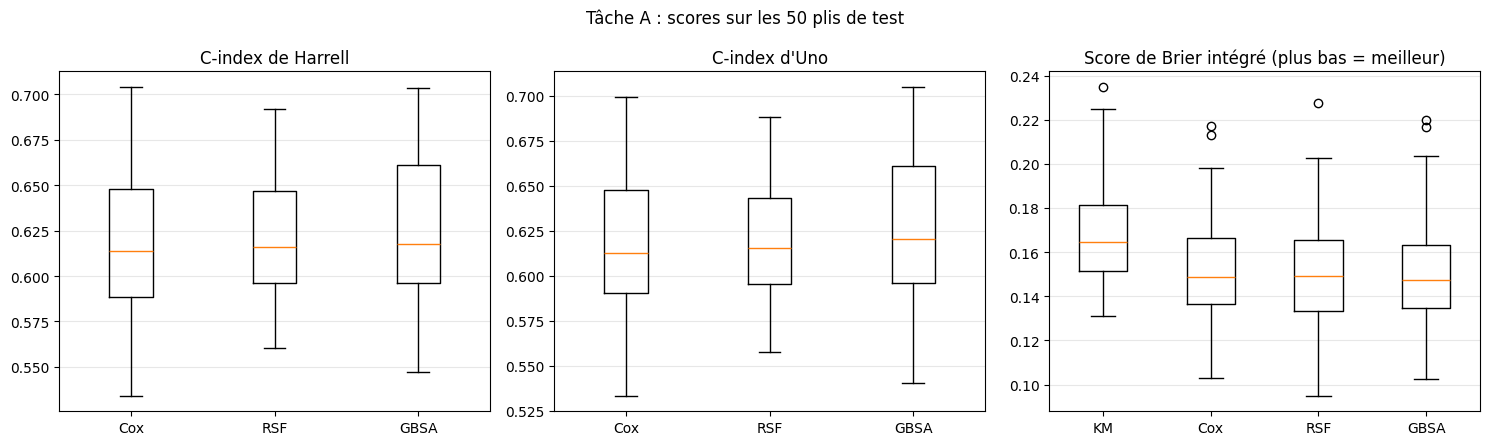

In [12]:
# ============================================================
# 3.4.c Distribution des scores par modèle
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (metric, title) in zip(axes, [("harrell_c", "C-index de Harrell"), ("uno_c", "C-index d'Uno"),
                                      ("ibs", "Score de Brier intégré (plus bas = meilleur)")]):
    shown = [m for m in MODELS if results.loc[results["model"] == m, metric].notna().any()]
    ax.boxplot([results.loc[results["model"] == m, metric].dropna() for m in shown], tick_labels=shown)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"Tâche A : scores sur les {N_FOLDS * N_REPEATS} plis de test")
plt.tight_layout()
plt.show()


### 3.5 Interprétation

In [13]:
# ============================================================
# 3.5 Interprétation (générée à partir des résultats)
# ============================================================
def mean_sd(model, metric):
    s = results.loc[results["model"] == model, metric]
    return f"{s.mean():.3f} (écart-type {s.std():.3f})"


lines = []
for m, v in verdicts.items():
    h, b = v["harrell"], v["ibs"]
    if v["better"]:
        verdict = "**meilleur que le modèle de Cox**"
    elif v["worse_c"]:
        verdict = "**moins bon que le modèle de Cox** (C-index significativement plus bas)"
    else:
        verdict = "**pas de différence nette avec le modèle de Cox**"
    lines.append(
        f"- **{m}** : C-index de Harrell {mean_sd(m, 'harrell_c')}, soit {h['différence moyenne']:+.3f} par rapport "
        f"au modèle de Cox (meilleur dans {h['plis où meilleur (%)']:.0f} % des plis, p corrigée = {h['p corrigée']:.3f}) ; "
        f"score de Brier intégré {mean_sd(m, 'ibs')}, soit {b['différence moyenne']:+.3f} "
        f"(p corrigée = {b['p corrigée']:.3f}) → {verdict}."
    )

km_test = tests[(tests["modèle"] == "Cox") & (tests["référence"] == "KM")].iloc[0]
any_better = any(v["better"] for v in verdicts.values())
if any_better:
    winners = ", ".join(m for m, v in verdicts.items() if v["better"])
    conclusion_A = (f"Selon la règle fixée en 3.4, {winners} prédit mieux la durée de vie des partis que le modèle de Cox.")
else:
    conclusion_A = ("Aucun modèle d'apprentissage automatique ne prédit mieux que le modèle de Cox selon la règle fixée "
                    "en 3.4 : **le modèle de Cox n'est pas surpassé**. Avec ce nombre de spells, la flexibilité des "
                    "forêts et du boosting n'apporte pas de gain de prédiction mesurable, ce qui conforte le choix du "
                    "modèle de Cox, plus simple et directement interprétable (hazard ratios, tests).")

cox_vs_km = ("améliore significativement" if km_test["p corrigée"] < ALPHA and km_test["différence moyenne"] < 0
             else "n'améliore pas significativement")
censored_total = int((static["event"] == 0).sum())
censored_min = int(results["censored_test"].min())
# Dispersion des scores entre plis, comparée aux écarts moyens entre modèles (métriques fondées sur la censure)
noise_lines = []
for metric, label_metric in [("uno_c", "C-index d'Uno"), ("ibs", "score de Brier intégré")]:
    sd_between_folds = results[results["model"].isin(["Cox", "RSF", "GBSA"])].groupby("model")[metric].std().mean()
    largest_gap = tests.loc[(tests["référence"] == "Cox") & (tests["métrique"] == metric), "différence moyenne"].abs().max()
    relation = "plus grande que" if sd_between_folds > largest_gap else "plus petite que"
    noise_lines.append(f"pour le {label_metric}, la dispersion entre plis (écart-type moyen {sd_between_folds:.3f}) est "
                       f"{relation} le plus grand écart moyen avec le modèle de Cox ({largest_gap:.3f})")

display(Markdown(
    "**Question 1 : un modèle flexible prédit-il mieux la durée de vie des partis que le modèle de Cox, "
    "sur des partis qu'il n'a jamais vus ?**\n\n"
    f"Le modèle de Cox atteint un C-index de Harrell de {mean_sd('Cox', 'harrell_c')} et un C-index d'Uno de "
    f"{mean_sd('Cox', 'uno_c')} sur les {N_FOLDS * N_REPEATS} plis de test. Par rapport à Kaplan-Meier, qui prédit la "
    f"même courbe pour tous les partis, il {cox_vs_km} le score de Brier intégré "
    f"({mean_sd('Cox', 'ibs')} contre {mean_sd('KM', 'ibs')}, p corrigée = {km_test['p corrigée']:.3f}).\n\n"
    + "\n".join(lines) + "\n\n"
    + conclusion_A + "\n\n"
    f"> **⚠️ Limite :** seuls {censored_total} spells sont censurés, et certains plis de test n'en contiennent que "
    f"{censored_min}. Le C-index d'Uno et le score de Brier, qui reposent sur la censure, sont donc bruités : "
    + " ; ".join(noise_lines) + "."
))


**Question 1 : un modèle flexible prédit-il mieux la durée de vie des partis que le modèle de Cox, sur des partis qu'il n'a jamais vus ?**

Le modèle de Cox atteint un C-index de Harrell de 0.616 (écart-type 0.043) et un C-index d'Uno de 0.616 (écart-type 0.044) sur les 50 plis de test. Par rapport à Kaplan-Meier, qui prédit la même courbe pour tous les partis, il améliore significativement le score de Brier intégré (0.152 (écart-type 0.025) contre 0.169 (écart-type 0.024), p corrigée = 0.038).

- **RSF** : C-index de Harrell 0.620 (écart-type 0.033), soit +0.004 par rapport au modèle de Cox (meilleur dans 62 % des plis, p corrigée = 0.784) ; score de Brier intégré 0.152 (écart-type 0.026), soit -0.001 (p corrigée = 0.891) → **pas de différence nette avec le modèle de Cox**.
- **GBSA** : C-index de Harrell 0.624 (écart-type 0.041), soit +0.009 par rapport au modèle de Cox (meilleur dans 64 % des plis, p corrigée = 0.578) ; score de Brier intégré 0.149 (écart-type 0.026), soit -0.003 (p corrigée = 0.527) → **pas de différence nette avec le modèle de Cox**.

Aucun modèle d'apprentissage automatique ne prédit mieux que le modèle de Cox selon la règle fixée en 3.4 : **le modèle de Cox n'est pas surpassé**. Avec ce nombre de spells, la flexibilité des forêts et du boosting n'apporte pas de gain de prédiction mesurable, ce qui conforte le choix du modèle de Cox, plus simple et directement interprétable (hazard ratios, tests).

> **⚠️ Limite :** seuls 29 spells sont censurés, et certains plis de test n'en contiennent que 5. Le C-index d'Uno et le score de Brier, qui reposent sur la censure, sont donc bruités : pour le C-index d'Uno, la dispersion entre plis (écart-type moyen 0.040) est plus grande que le plus grand écart moyen avec le modèle de Cox (0.009) ; pour le score de Brier intégré, la dispersion entre plis (écart-type moyen 0.026) est plus grande que le plus grand écart moyen avec le modèle de Cox (0.003).

## 4. Tâche B : hasard en temps discret

### 4.1 Cadre : le hasard en temps discret

Dans le jeu time-varying, chaque ligne est **une année au pouvoir** d'un parti. La cible est binaire : le parti tombe-t-il **pendant cette année** ? Un modèle estime donc, pour chaque parti-année, la probabilité

$$P(\text{chute en } t \mid \text{au pouvoir au début de } t,\ \text{covariables}),$$

c'est-à-dire le **hasard en temps discret**. Les covariables institutionnelles sont constantes au sein d'un spell ; les variables macro (PIB, Polity2, conflit) sont celles de l'année précédente, ce qui évite d'utiliser la situation de l'année même de la chute. Tous les modèles reçoivent la même information : les covariables et le temps écoulé depuis l'accession au pouvoir (`start`).

Les lignes d'un même spell (et plus largement d'un même pays) sont très liées : mêmes covariables institutionnelles, contexte national commun. Si elles se répartissaient entre apprentissage et test, le modèle pourrait reconnaître le parti au lieu d'apprendre une relation générale. Les plis de la Section 2 regroupent donc **toutes les années d'un pays dans le même pli**.

### 4.2 Modèles

* **Temps seul** : régression logistique sur des classes de durée au pouvoir (0-2, 3-5, 6-10, 11-20, plus de 20 ans). Elle mesure ce que la seule durée permet de prédire.
* **Cox time-varying** : `CoxTimeVaryingFitter(penalizer=0.01)`, le modèle de `final_panel.ipynb` (Section 5.2), converti en probabilités annuelles $p = 1 - \exp(-h_0 \, e^{x'\beta})$. Le hasard de base $h_0$ est **constant par morceaux** sur les mêmes classes de durée : $h_0(b) = d_b / \sum_{i \in b} e^{x_i'\beta}$, où $d_b$ est le nombre de chutes de la classe $b$ dans le pli d'apprentissage (estimateur de Breslow agrégé par classe). L'estimateur de Breslow brut, en escalier, n'augmente qu'aux durées où une chute a été observée dans le pli d'apprentissage : il attribue une probabilité **nulle** à toute année de test d'une durée sans chute à l'apprentissage, ce qui est un artefact de l'estimateur et pénaliserait injustement le modèle de Cox. L'ampleur de cet artefact est mesurée en 4.3.
* **Logistique** : régression logistique pénalisée (L2) sur les covariables standardisées et les mêmes classes de durée, le pendant paramétrique en temps discret du modèle de Cox ; $C$ est choisi parmi {0,01 ; 0,1 ; 1 ; 10}.
* **LightGBM** : gradient boosting d'arbres de classification sur les covariables et la durée au pouvoir brute (`start`), qui peut capter des effets non linéaires et des interactions, notamment entre la durée et les covariables.

Les classes de durée prévues initialement isolaient la première année (0, 1-2, 3-5...) ; la classe « 0 » ne compte presque aucune chute, car la plupart des spells n'entrent dans le jeu time-varying qu'après leur première année (faute de valeur retardée des variables macro). Une classe sans chute dans un pli d'apprentissage reçoit une probabilité nulle, le même artefact que l'estimateur en escalier : elle est donc fusionnée avec la classe 1-2 (effectifs ci-dessous).

Les hyperparamètres sont choisis à l'intérieur de chaque pli d'apprentissage (validation croisée interne à 3 plis groupée par pays, perte logarithmique). Aucun rééchantillonnage ni pondération des classes n'est utilisé : les probabilités prédites doivent rester calibrées.

In [14]:
# ============================================================
# 4.2 Spécification des modèles et vérification du modèle de Cox time-varying
# ============================================================
from lifelines import CoxTimeVaryingFitter
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Effectifs avec les classes initialement prévues : la première année ne compte presque aucune chute
initial_bins = pd.cut(tv["start"], [-1, 0, 2, 5, 10, 20, np.inf], labels=["0", "1-2", "3-5", "6-10", "11-20", ">20"])
display(Markdown("Classes de durée initialement prévues :"))
display(pd.DataFrame({"parti-années": tv.groupby(initial_bins, observed=True).size(),
                      "chutes": tv.groupby(initial_bins, observed=True)["event"].sum().astype(int)}).T)

# Classes retenues : la première année est fusionnée avec 1-2 ans
TIME_BINS = [-1, 2, 5, 10, 20, np.inf]
TIME_LABELS = ["0-2", "3-5", "6-10", "11-20", ">20"]
BIN_COLS = [f"duree_{label}" for label in TIME_LABELS[1:]]      # classe "0-2" = référence
tv["time_bin"] = pd.cut(tv["start"], TIME_BINS, labels=TIME_LABELS)
tv["time_bin_code"] = tv["time_bin"].cat.codes
for label, col in zip(TIME_LABELS[1:], BIN_COLS):
    tv[col] = (tv["time_bin"] == label).astype(float)
display(Markdown("Classes de durée retenues :"))

TV_KEYS_FIT = ["spell_id", "start", "stop", "event"]
LOGIT_GRID = {"clf__C": [0.01, 0.1, 1, 10]}
LGBM_GRID = {"num_leaves": [4, 8, 16], "min_child_samples": [20, 50], "n_estimators": [100, 300]}
MODELS_B = ["Temps seul", "Cox time-varying", "Logistique", "LightGBM"]

display(pd.DataFrame({"parti-années": tv.groupby("time_bin", observed=True).size(),
                      "chutes": tv.groupby("time_bin", observed=True)["event"].sum().astype(int)}).T)


def fit_ctv(train, features):
    return CoxTimeVaryingFitter(penalizer=COX_PENALIZER).fit(
        train[TV_KEYS_FIT + features], id_col="spell_id", start_col="start", stop_col="stop", event_col="event")


def ctv_piecewise_probability(model, train, test, features):
    """Probabilités annuelles du Cox time-varying avec un hasard de base constant par classe de durée."""
    risk_train = model.predict_partial_hazard(train[features]).values
    bins_train = train["time_bin_code"].values
    h0 = (pd.Series(train["event"].values).groupby(bins_train).sum()
          / pd.Series(risk_train).groupby(bins_train).sum())
    h_test = h0.reindex(test["time_bin_code"].values).values
    assert not np.isnan(h_test).any(), "classe de durée absente du pli d'apprentissage"
    return 1 - np.exp(-h_test * model.predict_partial_hazard(test[features]).values)


def ctv_step_probability(model, test, features):
    """Diagnostic : probabilités avec l'estimateur de Breslow brut (en escalier)."""
    H0 = model.baseline_cumulative_hazard_.iloc[:, 0]
    def H(t):
        idx = np.searchsorted(H0.index.values, t, side="right") - 1
        return np.where(idx >= 0, H0.values[np.clip(idx, 0, None)], 0.0)
    dH = H(test["stop"].values) - H(test["start"].values)
    return 1 - np.exp(-dH * model.predict_partial_hazard(test[features]).values)


# Vérification : estimé sur toutes les lignes, le modèle reproduit les HR time-varying de final_panel (tableau 5.3)
ctv_full = fit_ctv(tv, TV_FEATURES)
hr_tv_final_panel = table_53["HR time-varying"].dropna()
ctv_check = pd.DataFrame({"HR final_panel": hr_tv_final_panel,
                          "HR recalculé": np.exp(ctv_full.params_).round(3).reindex(hr_tv_final_panel.index)})
assert set(hr_tv_final_panel.index) == set(TV_FEATURES), "covariables différentes de final_panel"
assert (ctv_check["HR recalculé"] == ctv_check["HR final_panel"]).all(), "hazard ratios différents de final_panel"
display(ctv_check)
display(Markdown(
    f"**Vérification réussie.** Les {len(ctv_check)} hazard ratios du modèle de Cox time-varying estimé ici sont "
    "identiques, à trois décimales, à ceux de `final_panel.ipynb` (Section 5.2)."
))


Classes de durée initialement prévues :

start,0,1-2,3-5,6-10,11-20,>20
parti-années,50,378,457,590,821,1357
chutes,1,37,36,36,40,44


Classes de durée retenues :

time_bin,0-2,3-5,6-10,11-20,>20
parti-années,428,457,590,821,1357
chutes,38,36,36,40,44


,HR final_panel,HR recalculé
Marxist?,0.758,0.758
Gov_Repressive,0.931,0.931
Gov_Clientelist,0.490,0.490
Gov_Non code,0.639,0.639
Origin_Communist,0.556,0.556
Origin_Elite Coalition,0.872,0.872
Origin_Independence,0.618,0.618
Origin_Merger/Split,1.052,1.052
Origin_Military,1.151,1.151
Origin_Revolution,0.589,0.589


**Vérification réussie.** Les 13 hazard ratios du modèle de Cox time-varying estimé ici sont identiques, à trois décimales, à ceux de `final_panel.ipynb` (Section 5.2).

### 4.3 Métriques et validation croisée

Sur chacun des 50 plis de test, au niveau des parti-années :
* **ROC-AUC** : capacité à donner une probabilité plus élevée aux années où le parti tombe (0,5 = hasard).
* **PR-AUC** (précision moyenne) : plus exigeante quand l'événement est rare ; son niveau de hasard est la **fréquence des chutes** du pli, reportée à côté.
* **Score de Brier** et **perte logarithmique** : qualité des probabilités elles-mêmes (plus bas = meilleur) ; la perte logarithmique pénalise fortement les probabilités proches de 0 pour des chutes observées.
* **Calibrage global** : probabilité moyenne prédite comparée à la fréquence observée des chutes.

In [15]:
# ============================================================
# 4.3 Évaluation sur les 50 plis (5 plis x 10 répétitions)
# ============================================================
folds_tv = (pd.read_csv(DATA_DIR / "ml_folds.csv", dtype={"row_id": str})
            .query("dataset == 'timevarying'").astype({"row_id": int}))


def inner_splits_tv(train):
    splitter = StratifiedGroupKFold(n_splits=N_INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    return list(splitter.split(train, train["event"], train["Country"]))


results_B, oof_B, step_diagnostics = [], [], []
start_B = time.perf_counter()
for rep in range(N_REPEATS):
    assignment = folds_tv[folds_tv["repetition"] == rep].set_index("row_id").loc[tv["row_id"], "fold"].values
    for k in range(N_FOLDS):
        train, test = tv[assignment != k], tv[assignment == k]
        features = [c for c in TV_FEATURES if train[c].var() > 0]
        inner = inner_splits_tv(train)
        probs, params = {}, {}

        time_only = LogisticRegression(C=1e6, max_iter=5000).fit(train[BIN_COLS], train["event"])
        probs["Temps seul"], params["Temps seul"] = time_only.predict_proba(test[BIN_COLS])[:, 1], {}

        ctv = fit_ctv(train, features)
        probs["Cox time-varying"] = ctv_piecewise_probability(ctv, train, test, features)
        params["Cox time-varying"] = {"penalizer": COX_PENALIZER}
        p_step = ctv_step_probability(ctv, test, features)
        step_diagnostics.append({"repetition": rep, "fold": k, "share_zero": float((p_step == 0).mean()),
                                 "events_zero": int(((p_step == 0) & (test["event"] == 1)).sum()),
                                 "events": int(test["event"].sum())})

        logit = Pipeline([("prep", ColumnTransformer([("scale", StandardScaler(), features),
                                                      ("bins", "passthrough", BIN_COLS)])),
                          ("clf", LogisticRegression(max_iter=5000))])
        search = GridSearchCV(logit, LOGIT_GRID, cv=inner, scoring="neg_log_loss", n_jobs=-1)
        search.fit(train[features + BIN_COLS], train["event"])
        probs["Logistique"] = search.predict_proba(test[features + BIN_COLS])[:, 1]
        params["Logistique"] = {"C": search.best_params_["clf__C"]}

        lgbm = LGBMClassifier(learning_rate=0.05, reg_lambda=1.0, verbose=-1, random_state=RANDOM_STATE, n_jobs=1)
        search = GridSearchCV(lgbm, LGBM_GRID, cv=inner, scoring="neg_log_loss", n_jobs=-1)
        search.fit(train[features + ["start"]], train["event"])
        probs["LightGBM"], params["LightGBM"] = search.predict_proba(test[features + ["start"]])[:, 1], search.best_params_

        for name in MODELS_B:
            p = probs[name]
            results_B.append({
                "model": name, "repetition": rep, "fold": k, "n_train": len(train), "n_test": len(test),
                "events_test": int(test["event"].sum()), "event_rate": float(test["event"].mean()),
                "roc_auc": roc_auc_score(test["event"], p), "pr_auc": average_precision_score(test["event"], p),
                "brier": brier_score_loss(test["event"], p), "log_loss": log_loss(test["event"], p, labels=[0, 1]),
                "mean_predicted": float(p.mean()), "hyperparameters": json.dumps(params[name]),
            })
            oof_B.append(pd.DataFrame({"row_id": test["row_id"].values, "repetition": rep,
                                       "model": name, "probability": p}))
    print(f"Répétition {rep + 1}/{N_REPEATS} terminée ({time.perf_counter() - start_B:.0f} s)")

results_B = pd.DataFrame(results_B)
oof_B = pd.concat(oof_B, ignore_index=True)
step_diagnostics = pd.DataFrame(step_diagnostics)
runtime_taskB = time.perf_counter() - start_B
results_B.to_csv(DATA_DIR / "ml_results_taskB.csv", index=False)
oof_B.to_csv(DATA_DIR / "ml_oof_taskB.csv", index=False)
print(f"Résultats : {DATA_DIR / 'ml_results_taskB.csv'} ({len(results_B)} lignes) ; "
      f"prédictions hors pli : {DATA_DIR / 'ml_oof_taskB.csv'} ({len(oof_B)} lignes) ; {runtime_taskB / 60:.1f} min")

for name in ["Logistique", "LightGBM"]:
    counts = results_B.loc[results_B["model"] == name, "hyperparameters"].value_counts()
    display(Markdown(f"**{name}** — hyperparamètres retenus (nombre de plis sur {counts.sum()}) :"))
    with pd.option_context("display.max_colwidth", None):
        display(counts.rename("plis").to_frame())

display(Markdown(
    f"**Diagnostic de l'estimateur de Breslow brut.** Avec le hasard de base en escalier, "
    f"{step_diagnostics['share_zero'].mean() * 100:.1f} % des parti-années de test reçoivent en moyenne une "
    f"probabilité de chute nulle, et {step_diagnostics['events_zero'].sum()} des {step_diagnostics['events'].sum()} chutes "
    f"de test ({step_diagnostics['events_zero'].sum() / step_diagnostics['events'].sum() * 100:.1f} %) tombent dans "
    "ces années. C'est pourquoi le modèle de Cox time-varying est évalué avec un hasard de base constant par classe "
    "de durée (Section 4.2)."
))


Répétition 1/10 terminée (12 s)


Répétition 2/10 terminée (16 s)


Répétition 3/10 terminée (21 s)


Répétition 4/10 terminée (25 s)


Répétition 5/10 terminée (29 s)


...

**Logistique** — hyperparamètres retenus (nombre de plis sur 50) :

,plis
hyperparameters,
"{""C"": 0.1}",28
"{""C"": 0.01}",21
"{""C"": 1}",1


**LightGBM** — hyperparamètres retenus (nombre de plis sur 50) :

,plis
hyperparameters,
"{""min_child_samples"": 50, ""n_estimators"": 100, ""num_leaves"": 4}",30
"{""min_child_samples"": 20, ""n_estimators"": 100, ""num_leaves"": 4}",20


**Diagnostic de l'estimateur de Breslow brut.** Avec le hasard de base en escalier, 16.7 % des parti-années de test reçoivent en moyenne une probabilité de chute nulle, et 296 des 1940 chutes de test (15.3 %) tombent dans ces années. C'est pourquoi le modèle de Cox time-varying est évalué avec un hasard de base constant par classe de durée (Section 4.2).

### 4.4 Comparaison avec le modèle de Cox time-varying

Comme en 3.4, nous comparons chaque modèle au modèle de Cox time-varying pli par pli, avec le **test t rééchantillonné corrigé** (Nadeau & Bengio, 2003), calculé ici avec les tailles moyennes des plis en parti-années.

**Règle de décision, fixée avant les résultats :** un modèle n'est déclaré « meilleur que le Cox time-varying » que si sa ROC-AUC est significativement plus élevée au seuil $\alpha$ **et** que sa perte logarithmique n'est pas significativement plus mauvaise. Nous testons aussi si les covariables apportent une information au-delà de la seule durée (Cox time-varying contre Temps seul, perte logarithmique).

In [16]:
# ============================================================
# 4.4.a Scores moyens par modèle
# ============================================================
METRICS_B = {"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC", "brier": "Brier", "log_loss": "Perte log.",
             "mean_predicted": "Probabilité moyenne prédite"}
table_B = pd.DataFrame({
    label: [f"{results_B.loc[results_B['model'] == m, metric].mean():.4f} ± "
            f"{results_B.loc[results_B['model'] == m, metric].std():.4f}" for m in MODELS_B]
    for metric, label in METRICS_B.items()
}, index=MODELS_B)
table_B["Fréquence observée des chutes"] = (f"{results_B['event_rate'].mean():.4f} ± "
                                            f"{results_B.loc[results_B['model'] == MODELS_B[0], 'event_rate'].std():.4f}")
display(Markdown("Moyenne ± écart-type sur les 50 plis de test (la fréquence observée est le niveau de hasard de la PR-AUC) :"))
display(table_B)


Moyenne ± écart-type sur les 50 plis de test (la fréquence observée est le niveau de hasard de la PR-AUC) :

,ROC-AUC,PR-AUC,Brier,Perte log.,Probabilité moyenne prédite,Fréquence observée des chutes
Temps seul,0.6019 ± 0.0355,0.0718 ± 0.0097,0.0500 ± 0.0015,0.2049 ± 0.0046,0.0531 ± 0.0018,0.0531 ± 0.0018
Cox time-varying,0.6732 ± 0.0344,0.1192 ± 0.0303,0.0494 ± 0.0015,0.1986 ± 0.0054,0.0533 ± 0.0059,0.0531 ± 0.0018
Logistique,0.6725 ± 0.0363,0.1246 ± 0.0318,0.0495 ± 0.0016,0.1990 ± 0.0059,0.0555 ± 0.0069,0.0531 ± 0.0018
LightGBM,0.6702 ± 0.0429,0.1156 ± 0.0261,0.0497 ± 0.0019,0.1998 ± 0.0070,0.0590 ± 0.0069,0.0531 ± 0.0018


In [17]:
# ============================================================
# 4.4.b Différences appariées et test t corrigé
# ============================================================
HIGHER_IS_BETTER_B = {"roc_auc": True, "pr_auc": True, "brier": False, "log_loss": False}
n_train_mean_B = results_B["n_train"].mean()
n_test_mean_B = results_B["n_test"].mean()


def corrected_ttest_B(d):
    J = len(d)
    t_stat = d.mean() / np.sqrt((1 / J + n_test_mean_B / n_train_mean_B) * d.var(ddof=1))
    return t_stat, 2 * stats.t.sf(abs(t_stat), df=J - 1)


def paired_B(model, reference, metric):
    a = results_B[results_B["model"] == model].set_index(["repetition", "fold"])[metric]
    b = results_B[results_B["model"] == reference].set_index(["repetition", "fold"])[metric]
    d = a - b
    t_stat, p = corrected_ttest_B(d)
    better = (d > 0) if HIGHER_IS_BETTER_B[metric] else (d < 0)
    return {"modèle": model, "référence": reference, "métrique": metric, "différence moyenne": d.mean(),
            "écart-type": d.std(ddof=1), "plis où meilleur (%)": better.mean() * 100,
            "t corrigé": t_stat, "p corrigée": p}


tests_B = pd.DataFrame([paired_B(m, "Cox time-varying", metric)
                        for m in ["Temps seul", "Logistique", "LightGBM"] for metric in HIGHER_IS_BETTER_B]
                       + [paired_B("Cox time-varying", "Temps seul", "log_loss")])
display(tests_B.round(4))

verdicts_B = {}
for m in ["Logistique", "LightGBM"]:
    auc = tests_B[(tests_B["modèle"] == m) & (tests_B["métrique"] == "roc_auc")].iloc[0]
    ll = tests_B[(tests_B["modèle"] == m) & (tests_B["métrique"] == "log_loss")].iloc[0]
    verdicts_B[m] = {
        "better": bool(auc["p corrigée"] < ALPHA and auc["différence moyenne"] > 0
                       and not (ll["p corrigée"] < ALPHA and ll["différence moyenne"] > 0)),
        "worse": bool(auc["p corrigée"] < ALPHA and auc["différence moyenne"] < 0),
        "auc": auc, "log_loss": ll,
    }


,modèle,référence,métrique,différence moyenne,écart-type,plis où meilleur (%),t corrigé,p corrigée
0,Temps seul,Cox time-varying,roc_auc,-0.0712,0.0330,4.0,-4.1588,0.0001
1,Temps seul,Cox time-varying,pr_auc,-0.0474,0.0276,0.0,-3.3048,0.0018
2,Temps seul,Cox time-varying,brier,0.0006,0.0005,14.0,2.2014,0.0324
3,Temps seul,Cox time-varying,log_loss,0.0063,0.0035,4.0,3.4412,0.0012
4,Logistique,Cox time-varying,roc_auc,-0.0006,0.0103,46.0,-0.1214,0.9039
5,Logistique,Cox time-varying,pr_auc,0.0054,0.0130,66.0,0.7992,0.4280
6,Logistique,Cox time-varying,brier,0.0000,0.0004,54.0,0.1828,0.8557
7,Logistique,Cox time-varying,log_loss,0.0004,0.0019,44.0,0.4131,0.6813
8,LightGBM,Cox time-varying,roc_auc,-0.0030,0.0267,52.0,-0.2168,0.8293
9,LightGBM,Cox time-varying,pr_auc,-0.0036,0.0212,48.0,-0.3292,0.7434


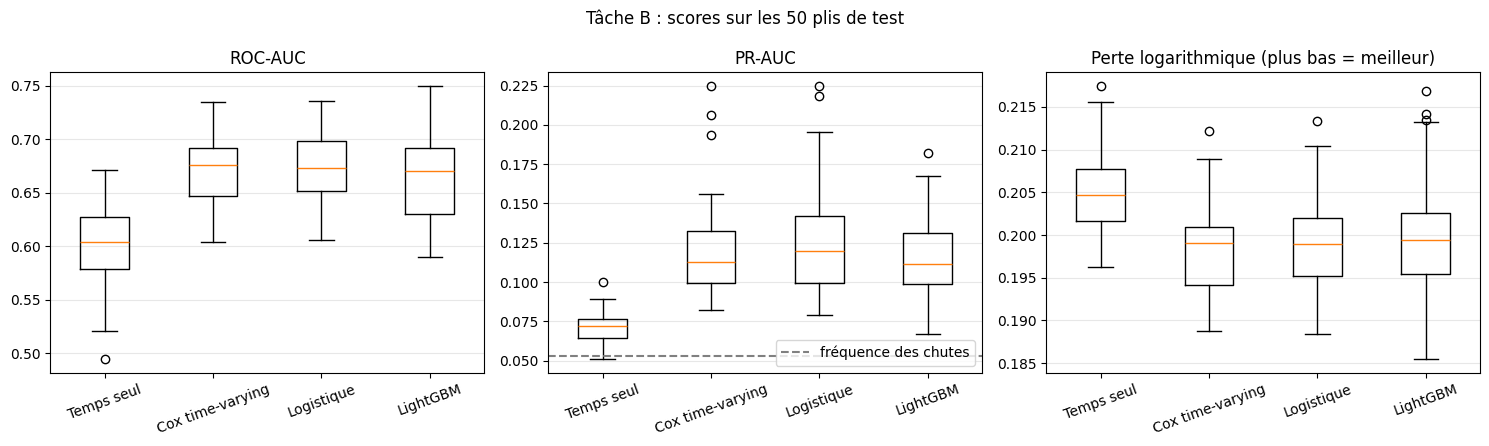

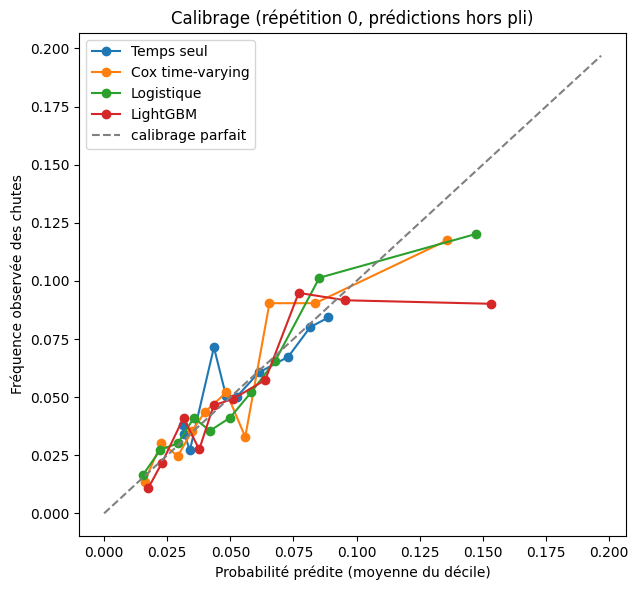

,probabilité moyenne prédite,fréquence observée,écart absolu moyen par décile
modèle,,,
Temps seul,0.0532,0.0531,0.0061
Cox time-varying,0.0532,0.0531,0.0096
Logistique,0.0553,0.0531,0.0079
LightGBM,0.0594,0.0531,0.0124


In [18]:
# ============================================================
# 4.4.c Distribution des scores et calibrage
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (metric, title) in zip(axes, [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"),
                                      ("log_loss", "Perte logarithmique (plus bas = meilleur)")]):
    ax.boxplot([results_B.loc[results_B["model"] == m, metric] for m in MODELS_B], tick_labels=MODELS_B)
    if metric == "pr_auc":
        ax.axhline(results_B["event_rate"].mean(), color="grey", linestyle="--", label="fréquence des chutes")
        ax.legend()
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle(f"Tâche B : scores sur les {N_FOLDS * N_REPEATS} plis de test")
plt.tight_layout()
plt.show()

# Courbe de calibrage : déciles de probabilité prédite, prédictions hors pli de la répétition 0
oof_rep0 = oof_B[oof_B["repetition"] == 0].merge(tv[["row_id", "event"]], on="row_id")
fig, ax = plt.subplots(figsize=(6.5, 6))
calibration_rows = []
for m in MODELS_B:
    d = oof_rep0[oof_rep0["model"] == m].copy()
    d["decile"] = pd.qcut(d["probability"], 10, labels=False, duplicates="drop")
    curve = d.groupby("decile").agg(predicted=("probability", "mean"), observed=("event", "mean"))
    ax.plot(curve["predicted"], curve["observed"], marker="o", label=m)
    calibration_rows.append({"modèle": m, "probabilité moyenne prédite": d["probability"].mean(),
                             "fréquence observée": d["event"].mean(),
                             "écart absolu moyen par décile": (curve["predicted"] - curve["observed"]).abs().mean()})
upper = oof_rep0["probability"].quantile(0.99)
ax.plot([0, upper], [0, upper], color="grey", linestyle="--", label="calibrage parfait")
ax.set_xlabel("Probabilité prédite (moyenne du décile)")
ax.set_ylabel("Fréquence observée des chutes")
ax.set_title("Calibrage (répétition 0, prédictions hors pli)")
ax.legend()
plt.tight_layout()
plt.show()
calibration_B = pd.DataFrame(calibration_rows).set_index("modèle")
display(calibration_B.round(4))


### 4.5 Interprétation

In [19]:
# ============================================================
# 4.5 Interprétation (générée à partir des résultats)
# ============================================================
def mean_sd_B(model, metric):
    s = results_B.loc[results_B["model"] == model, metric]
    return f"{s.mean():.3f} (écart-type {s.std():.3f})"


lines_B = []
for m, v in verdicts_B.items():
    a, ll = v["auc"], v["log_loss"]
    if v["better"]:
        verdict = "**meilleur que le modèle de Cox time-varying**"
    elif v["worse"]:
        verdict = "**moins bon que le modèle de Cox time-varying** (ROC-AUC significativement plus basse)"
    else:
        verdict = "**pas de différence nette avec le modèle de Cox time-varying**"
    lines_B.append(
        f"- **{m}** : ROC-AUC {mean_sd_B(m, 'roc_auc')}, soit {a['différence moyenne']:+.3f} par rapport au Cox "
        f"time-varying (meilleure dans {a['plis où meilleur (%)']:.0f} % des plis, p corrigée = {a['p corrigée']:.3f}) ; "
        f"perte logarithmique {mean_sd_B(m, 'log_loss')}, soit {ll['différence moyenne']:+.4f} "
        f"(p corrigée = {ll['p corrigée']:.3f}) → {verdict}."
    )

if any(v["better"] for v in verdicts_B.values()):
    winners_B = ", ".join(m for m, v in verdicts_B.items() if v["better"])
    conclusion_B = f"Selon la règle fixée en 4.4, {winners_B} prédit mieux le risque annuel de chute que le modèle de Cox time-varying."
else:
    conclusion_B = ("Aucun modèle ne prédit mieux le risque annuel de chute que le modèle de Cox time-varying selon la "
                    "règle fixée en 4.4 : **le modèle de Cox time-varying n'est pas surpassé**, ce qui conforte "
                    "l'usage du modèle interprétable de `final_panel.ipynb`.")

cov = tests_B[(tests_B["modèle"] == "Cox time-varying") & (tests_B["référence"] == "Temps seul")].iloc[0]
covariates_add = cov["p corrigée"] < ALPHA and cov["différence moyenne"] < 0
covariates_txt = (("Les covariables apportent une information significative" if covariates_add
                   else "Les covariables n'apportent pas d'information significative")
                  + " au-delà de la seule durée au pouvoir : "
                  f"la perte logarithmique du Cox time-varying est de {mean_sd_B('Cox time-varying', 'log_loss')} contre "
                  f"{mean_sd_B('Temps seul', 'log_loss')} pour la durée seule (différence {cov['différence moyenne']:+.4f}, "
                  f"p corrigée = {cov['p corrigée']:.3f}) ; ROC-AUC {mean_sd_B('Cox time-varying', 'roc_auc')} contre "
                  f"{mean_sd_B('Temps seul', 'roc_auc')}.")

# Événements perdus par le modèle time-varying (données macro manquantes), calculés sur le panel complet
panel = pd.read_csv(DATA_DIR / "arpd_panel_merged.csv", low_memory=False)
panel = panel[panel["Party"] != "N"]
spell_status = panel.groupby(["Country", "Party", "Year in Power"])["Censored"].first()
n_ended_spells = int((spell_status == 0).sum())
n_events_tv = int(tv["event"].sum())
event_rate_tv = tv["event"].mean() * 100
calib_cox = calibration_B.loc["Cox time-varying"]

display(Markdown(
    "**Question 1 (cadre time-varying) : un modèle flexible prédit-il mieux le risque annuel de chute que le "
    "modèle de Cox ?**\n\n"
    f"Le modèle de Cox time-varying atteint une ROC-AUC de {mean_sd_B('Cox time-varying', 'roc_auc')} et une PR-AUC de "
    f"{mean_sd_B('Cox time-varying', 'pr_auc')}, pour une fréquence des chutes de {results_B['event_rate'].mean():.3f} "
    f"par parti-année. Sur la répétition 0, sa probabilité moyenne prédite ({calib_cox['probabilité moyenne prédite']:.4f}) "
    f"est proche de la fréquence observée ({calib_cox['fréquence observée']:.4f}).\n\n"
    + "\n".join(lines_B) + "\n\n" + conclusion_B + "\n\n" + covariates_txt + "\n\n"
    f"> **⚠️ Limites :** (1) les chutes sont rares à l'échelle de la parti-année ({event_rate_tv:.1f} % des lignes), "
    "ce qui rend la PR-AUC et la perte logarithmique sensibles à quelques chutes par pli ; (2) le modèle de Cox "
    "time-varying de `final_panel.ipynb` ne regroupe pas ses erreurs standards par pays : c'est sans effet sur la "
    "prédiction évaluée ici, mais ses p-values sont probablement trop optimistes ; (3) le jeu time-varying ne "
    f"conserve que {n_events_tv} des {n_ended_spells} chutes du panel ({n_ended_spells - n_events_tv} chutes perdues "
    "faute de données macro complètes, voir `final_panel.ipynb`, Section 10)."
))


**Question 1 (cadre time-varying) : un modèle flexible prédit-il mieux le risque annuel de chute que le modèle de Cox ?**

Le modèle de Cox time-varying atteint une ROC-AUC de 0.673 (écart-type 0.034) et une PR-AUC de 0.119 (écart-type 0.030), pour une fréquence des chutes de 0.053 par parti-année. Sur la répétition 0, sa probabilité moyenne prédite (0.0532) est proche de la fréquence observée (0.0531).

- **Logistique** : ROC-AUC 0.673 (écart-type 0.036), soit -0.001 par rapport au Cox time-varying (meilleure dans 46 % des plis, p corrigée = 0.904) ; perte logarithmique 0.199 (écart-type 0.006), soit +0.0004 (p corrigée = 0.681) → **pas de différence nette avec le modèle de Cox time-varying**.
- **LightGBM** : ROC-AUC 0.670 (écart-type 0.043), soit -0.003 par rapport au Cox time-varying (meilleure dans 52 % des plis, p corrigée = 0.829) ; perte logarithmique 0.200 (écart-type 0.007), soit +0.0012 (p corrigée = 0.520) → **pas de différence nette avec le modèle de Cox time-varying**.

Aucun modèle ne prédit mieux le risque annuel de chute que le modèle de Cox time-varying selon la règle fixée en 4.4 : **le modèle de Cox time-varying n'est pas surpassé**, ce qui conforte l'usage du modèle interprétable de `final_panel.ipynb`.

Les covariables apportent une information significative au-delà de la seule durée au pouvoir : la perte logarithmique du Cox time-varying est de 0.199 (écart-type 0.005) contre 0.205 (écart-type 0.005) pour la durée seule (différence -0.0063, p corrigée = 0.001) ; ROC-AUC 0.673 (écart-type 0.034) contre 0.602 (écart-type 0.036).

> **⚠️ Limites :** (1) les chutes sont rares à l'échelle de la parti-année (5.3 % des lignes), ce qui rend la PR-AUC et la perte logarithmique sensibles à quelques chutes par pli ; (2) le modèle de Cox time-varying de `final_panel.ipynb` ne regroupe pas ses erreurs standards par pays : c'est sans effet sur la prédiction évaluée ici, mais ses p-values sont probablement trop optimistes ; (3) le jeu time-varying ne conserve que 194 des 247 chutes du panel (53 chutes perdues faute de données macro complètes, voir `final_panel.ipynb`, Section 10).

## 5. Comparaison

Les deux tâches répondent à la même question (question 1) dans deux cadres : la durée de vie d'un spell à partir de sa situation à l'entrée au pouvoir (Tâche A), et le risque de chute année par année à partir de la situation de l'année précédente (Tâche B). Le tableau rassemble, pour chaque modèle, la métrique de discrimination principale (C de Harrell en A, ROC-AUC en B) et la métrique de qualité des probabilités (score de Brier intégré en A, perte logarithmique en B), avec l'écart apparié au modèle de Cox de la tâche et la p-value du test t corrigé.

In [20]:
# ============================================================
# 5. Comparaison des deux tâches
# ============================================================
TASKS = {
    "A : survie par spell": {"results": results, "models": MODELS, "cox": "Cox", "baseline": "KM",
                             "tests": tests, "verdicts": verdicts, "disc": ("harrell_c", "C de Harrell", True),
                             "prob": ("ibs", "Brier intégré", False)},
    "B : hasard annuel": {"results": results_B, "models": MODELS_B, "cox": "Cox time-varying", "baseline": "Temps seul",
                          "tests": tests_B, "verdicts": verdicts_B, "disc": ("roc_auc", "ROC-AUC", True),
                          "prob": ("log_loss", "Perte log.", False)},
}


def paired_result(task, model, metric):
    """Écart moyen (modèle - Cox de la tâche) et p-value corrigée, lus dans les tests des sections 3.4 et 4.4."""
    t, cox = task["tests"], task["cox"]
    row = t[(t["modèle"] == model) & (t["référence"] == cox) & (t["métrique"] == metric)]
    if len(row):
        return row.iloc[0]["différence moyenne"], row.iloc[0]["p corrigée"]
    row = t[(t["modèle"] == cox) & (t["référence"] == model) & (t["métrique"] == metric)]
    if len(row):
        return -row.iloc[0]["différence moyenne"], row.iloc[0]["p corrigée"]
    return np.nan, np.nan


def verdict_text(task, model):
    if model == task["cox"]:
        return "référence"
    if model in task["verdicts"]:
        v = task["verdicts"][model]
        return "meilleur que Cox" if v["better"] else ("moins bon que Cox" if v.get("worse_c") or v.get("worse") else "pas de différence nette")
    metric, _, higher = task["prob"]
    diff, p = paired_result(task, model, metric)
    worse = (diff < 0) if higher else (diff > 0)
    return "sans covariable : moins bon que Cox" if (p < ALPHA and worse) else "sans covariable : pas de différence nette"


summary_rows = []
for task_name, task in TASKS.items():
    res = task["results"]
    for model in task["models"]:
        row = {"Tâche": task_name, "Modèle": model}
        for key in ["disc", "prob"]:
            metric, label, _ = task[key]
            s = res.loc[res["model"] == model, metric]
            row[f"{key}_métrique"] = label
            row[f"{key}_valeur"] = f"{s.mean():.3f} ± {s.std():.3f}" if s.notna().any() else "—"
            diff, p = paired_result(task, model, metric)
            row[f"{key}_écart"] = f"{diff:+.4f} (p = {p:.3f})" if not np.isnan(diff) else "—"
        row["Verdict"] = verdict_text(task, model)
        summary_rows.append(row)

summary_both = pd.DataFrame(summary_rows).rename(columns={
    "disc_métrique": "Discrimination", "disc_valeur": "moyenne ± é.-t.", "disc_écart": "écart vs Cox",
    "prob_métrique": "Probabilités", "prob_valeur": "moyenne ± é.-t. ", "prob_écart": "écart vs Cox "})
with pd.option_context("display.max_colwidth", None):
    display(summary_both.set_index(["Tâche", "Modèle"]))

ml_better = [f"{m} (Tâche {t[0]})" for t, task in TASKS.items() for m, v in task["verdicts"].items() if v["better"]]
ml_models = [f"{m} (Tâche {t[0]})" for t, task in TASKS.items() for m in task["verdicts"]]
if ml_better:
    q1_text = f"Selon les règles fixées en 3.4 et 4.4, {', '.join(ml_better)} prédit mieux que le modèle de Cox de sa tâche."
else:
    q1_text = (f"Dans les deux cadres, aucun des {len(ml_models)} modèles comparés au modèle de Cox "
               f"({', '.join(ml_models)}) ne prédit mieux que lui selon les règles fixées en 3.4 et 4.4 : "
               "**les modèles de Cox ne sont pas surpassés**, que la survie soit prédite à partir de la situation à "
               "l'entrée au pouvoir ou année par année.")
baseline_text = (
    f"Les covariables apportent bien de l'information : en Tâche A, le modèle de Cox "
    f"{'améliore significativement' if km_test['p corrigée'] < ALPHA and km_test['différence moyenne'] < 0 else 'n améliore pas significativement'} "
    f"le score de Brier intégré par rapport à Kaplan-Meier (écart {km_test['différence moyenne']:+.4f}, p corrigée = "
    f"{km_test['p corrigée']:.3f}) ; en Tâche B, le Cox time-varying "
    f"{'améliore significativement' if cov['p corrigée'] < ALPHA and cov['différence moyenne'] < 0 else 'n améliore pas significativement'} "
    f"la perte logarithmique par rapport à la durée seule (écart {cov['différence moyenne']:+.4f}, p corrigée = "
    f"{cov['p corrigée']:.3f})."
).replace("n améliore", "n'améliore")
display(Markdown("**Question 1 : un modèle flexible prédit-il mieux que le modèle de Cox ?**\n\n" + q1_text + "\n\n" + baseline_text))


Discrimination moyenne ± é.-t.  \
Tâche                Modèle                                            
A : survie par spell KM                 C de Harrell               —   
                     Cox                C de Harrell   0.616 ± 0.043   
                     RSF                C de Harrell   0.620 ± 0.033   
                     GBSA               C de Harrell   0.624 ± 0.041   
B : hasard annuel    Temps seul              ROC-AUC   0.602 ± 0.036   
                     Cox time-varying        ROC-AUC   0.673 ± 0.034   
                     Logistique              ROC-AUC   0.673 ± 0.036   
                     LightGBM                ROC-AUC   0.670 ± 0.043   

                                              écart vs Cox   Probabilités  \
Tâche                Modèle                                                 
A : survie par spell KM                                  —  Brier intégré   
                     Cox                                 —  Brier intégré   
                     RSF               +0.0040 (p = 0.784)  Brier intégré   
                     GBSA              +0.0088 (p = 0.578)  Brier intégré   
B : hasard annuel    Temps seul        -0.0712 (p = 0.000)     Perte log.   
                     Cox time-varying                    —     Perte log.   
                     Logistique        -0.0006 (p = 0.904)     Perte log.   
                     LightGBM          -0.0030 (p = 0.829)     Perte log.   

                                      moyenne ± é.-t.         écart vs Cox   \
Tâche                Modèle                                                   
A : survie par spell KM                  0.169 ± 0.024  +0.0167 (p = 0.038)   
                     Cox                 0.152 ± 0.025                    —   
                     RSF                 0.152 ± 0.026  -0.0008 (p = 0.891)   
                     GBSA                0.149 ± 0.026  -0.0032 (p = 0.527)   
B : hasard annuel    Temps seul          0.205 ± 0.005  +0.0063 (p = 0.001)   
                     Cox time-varying    0.199 ± 0.005                    —   
                     Logistique          0.199 ± 0.006  +0.0004 (p = 0.681)   
                     LightGBM            0.200 ± 0.007  +0.0012 (p = 0.520)   

                                                                   Verdict  
Tâche                Modèle                                                 
A : survie par spell KM                sans covariable : moins bon que Cox  
                     Cox                                         référence  
                     RSF                           pas de différence nette  
                     GBSA                          pas de différence nette  
B : hasard annuel    Temps seul        sans covariable : moins bon que Cox  
                     Cox time-varying                            référence  
                     Logistique                    pas de différence nette  
                     LightGBM                      pas de différence nette

**Question 1 : un modèle flexible prédit-il mieux que le modèle de Cox ?**

Dans les deux cadres, aucun des 4 modèles comparés au modèle de Cox (RSF (Tâche A), GBSA (Tâche A), Logistique (Tâche B), LightGBM (Tâche B)) ne prédit mieux que lui selon les règles fixées en 3.4 et 4.4 : **les modèles de Cox ne sont pas surpassés**, que la survie soit prédite à partir de la situation à l'entrée au pouvoir ou année par année.

Les covariables apportent bien de l'information : en Tâche A, le modèle de Cox améliore significativement le score de Brier intégré par rapport à Kaplan-Meier (écart -0.0167, p corrigée = 0.038) ; en Tâche B, le Cox time-varying améliore significativement la perte logarithmique par rapport à la durée seule (écart -0.0063, p corrigée = 0.001).

## 6. Interprétation

Les sections 3 et 4 ont établi quel modèle **prédit** le mieux ; cette section cherche à comprendre **ce que les modèles ont appris** (questions 2 et 3). Les modèles d'interprétation sont ré-estimés sur les 5 plis d'apprentissage de la **répétition 0** seulement, avec les hyperparamètres retenus pour ces plis en 3.3 et 4.3, et toutes les mesures (importance par permutation, dépendance partielle, valeurs SHAP) sont calculées sur les plis de test correspondants (hors échantillon). Une seule répétition suffit : l'évaluation sur 50 plis a déjà été faite, et l'interprétation ne demande pas de la répéter.

In [21]:
# ============================================================
# 6.0 Ré-estimation des modèles sur les plis de la répétition 0
# ============================================================
import math

import shap

INTERP_REP = 0
folds_all = pd.read_csv(DATA_DIR / "ml_folds.csv", dtype={"row_id": str})
assign_A = (folds_all.query("dataset == 'static' and repetition == @INTERP_REP")
            .set_index("row_id").loc[static["spell_id"], "fold"].values)
assign_B = (folds_all.query("dataset == 'timevarying' and repetition == @INTERP_REP").astype({"row_id": int})
            .set_index("row_id").loc[tv["row_id"], "fold"].values)


def recorded_params(res, model, fold):
    row = res[(res["model"] == model) & (res["repetition"] == INTERP_REP) & (res["fold"] == fold)]
    return json.loads(row["hyperparameters"].iloc[0])


interp_A, interp_B = [], []
for k in range(N_FOLDS):
    # Tâche A : Cox, RSF, GBSA
    train, test = static[assign_A != k], static[assign_A == k]
    feats = [c for c in STATIC_FEATURES if train[c].var() > 0]
    y_tr = Surv.from_arrays(event=train["event"].astype(bool), time=train["duration"])
    cox = CoxPHFitter(penalizer=COX_PENALIZER).fit(train[SURV_COLS + feats], "duration", "event")
    rsf = RandomSurvivalForest(n_estimators=500, random_state=RANDOM_STATE,
                               **recorded_params(results, "RSF", k)).fit(train[feats], y_tr)
    gbsa = GradientBoostingSurvivalAnalysis(loss="coxph", subsample=0.8, random_state=RANDOM_STATE,
                                            **recorded_params(results, "GBSA", k)).fit(train[feats], y_tr)
    interp_A.append({"fold": k, "test": test, "features": feats, "cox": cox, "models": {
        "Cox": lambda X, m=cox, f=feats: m.predict_partial_hazard(X[f]).values,
        "RSF": lambda X, m=rsf, f=feats: m.predict(X[f]),
        "GBSA": lambda X, m=gbsa, f=feats: m.predict(X[f]),
    }, "rsf": rsf})
    # Tâche B : Cox time-varying, LightGBM
    train, test = tv[assign_B != k], tv[assign_B == k]
    feats = [c for c in TV_FEATURES if train[c].var() > 0]
    ctv = fit_ctv(train, feats)
    lgbm = LGBMClassifier(learning_rate=0.05, reg_lambda=1.0, verbose=-1, random_state=RANDOM_STATE, n_jobs=1,
                          **recorded_params(results_B, "LightGBM", k)).fit(train[feats + ["start"]], train["event"])
    risk_train = ctv.predict_partial_hazard(train[feats]).values
    h0_bins = (pd.Series(train["event"].values).groupby(train["time_bin_code"].values).sum()
               / pd.Series(risk_train).groupby(train["time_bin_code"].values).sum())
    interp_B.append({"fold": k, "train": train, "test": test, "features": feats, "ctv": ctv, "lgbm": lgbm,
                     "h0_bins": h0_bins, "models": {
        "Cox time-varying": lambda X, m=ctv, tr=train, f=feats: ctv_piecewise_probability(m, tr, X, f),
        "LightGBM": lambda X, m=lgbm, f=feats: m.predict_proba(X[f + ["start"]])[:, 1],
    }})
print(f"Modèles ré-estimés sur les {N_FOLDS} plis de la répétition {INTERP_REP}.")


Modèles ré-estimés sur les 5 plis de la répétition 0.


### 6.1 Importance par permutation

L'importance d'une variable est la **dégradation du score sur le pli de test** quand on mélange aléatoirement ses valeurs, ce qui casse son lien avec la survie : baisse du C-index de Harrell en Tâche A, hausse de la perte logarithmique en Tâche B (plus la dégradation est forte, plus la variable compte). Les indicatrices d'un même facteur sont permutées ensemble (« Origin » pour toutes les modalités d'origine, « Gouvernance » pour la stratégie de gouvernance), chaque autre covariable seule ; 20 permutations par pli. La durée au pouvoir n'est pas permutée en Tâche B : c'est la variable de temps, pas une covariable.

**Critère de cohérence avec le modèle de Cox, fixé avant les résultats :** les facteurs significatifs au seuil $\alpha$ dans le modèle de Cox de `final_panel.ipynb` (pour un facteur à plusieurs indicatrices, la plus petite p-value) doivent tous figurer parmi les $k$ premiers du classement par permutation, avec $k$ égal à la moitié (arrondie au supérieur) du nombre de facteurs. Lorsque plus de la moitié des facteurs sont significatifs, ce seuil serait impossible à atteindre même pour un classement parfait : $k$ est alors le nombre de facteurs significatifs.

In [22]:
# ============================================================
# 6.1 Importance par permutation (plis de test de la répétition 0)
# ============================================================
N_PERMUTATIONS = 20


def factor_groups(features):
    groups = {"Origin": [c for c in features if c.startswith("Origin_")],
              "Gouvernance": [c for c in features if c.startswith("Gov_")]}
    groups.update({c: [c] for c in features if not c.startswith(("Origin_", "Gov_"))})
    return {g: cols for g, cols in groups.items() if cols}


def permuted(X, cols, rng):
    Xp = X.copy()
    Xp[cols] = X[cols].values[rng.permutation(len(X))]
    return Xp


importance_rows = []
for task, folds_info in [("A", interp_A), ("B", interp_B)]:
    for info in folds_info:
        test, k = info["test"], info["fold"]
        for name, predict in info["models"].items():
            if task == "A":
                y_ev, y_t = test["event"].astype(bool), test["duration"]
                score = lambda X: concordance_index_censored(y_ev, y_t, predict(X))[0]
                base = score(test)
            else:
                score = lambda X: log_loss(test["event"], predict(X), labels=[0, 1])
                base = score(test)
            for group, cols in factor_groups(info["features"]).items():
                for p in range(N_PERMUTATIONS):
                    rng = np.random.RandomState(RANDOM_STATE + 1000 * k + p)
                    value = score(permuted(test, cols, rng))
                    importance_rows.append({"tâche": task, "modèle": name, "pli": k, "facteur": group,
                                            "importance": (base - value) if task == "A" else (value - base)})
importance = pd.DataFrame(importance_rows)

# Classement et comparaison avec les p-values des modèles de Cox de final_panel (tableau 5.3)
cox_p = {"A": table_53["p statique"].dropna(), "B": table_53["p time-varying"].dropna()}


def factor_p(task, group):
    p = cox_p[task]
    if group == "Origin":
        return p[[i for i in p.index if i.startswith("Origin_")]].min()
    if group == "Gouvernance":
        return p[[i for i in p.index if i.startswith("Gov_")]].min()
    return p[group]


ranking_tables, consistency = {}, []
for (task, model), d in importance.groupby(["tâche", "modèle"], sort=False):
    tab = (d.groupby("facteur")["importance"].agg(["mean", "std"]).sort_values("mean", ascending=False)
           .rename(columns={"mean": "importance moyenne", "std": "écart-type"}))
    tab["rang"] = np.arange(1, len(tab) + 1)
    tab["p Cox (final_panel)"] = [factor_p(task, g) for g in tab.index]
    n_sig = int((tab["p Cox (final_panel)"] < ALPHA).sum())
    top_k = max(math.ceil(len(tab) / 2), n_sig)
    sig = tab[tab["p Cox (final_panel)"] < ALPHA]
    ranking_tables[(task, model)] = tab
    consistency.append({"tâche": task, "modèle": model, "facteurs": len(tab), "significatifs dans Cox": n_sig,
                        "k": top_k, "significatifs dans le top k": int((sig["rang"] <= top_k).sum()),
                        "cohérent": bool((sig["rang"] <= top_k).all()),
                        "hors du top k": ", ".join(sig.index[sig["rang"] > top_k]) or "—"})
    display(Markdown(f"**Tâche {task} — {model}** ({'baisse du C-index' if task == 'A' else 'hausse de la perte logarithmique'}) :"))
    display(tab.round(4))
consistency = pd.DataFrame(consistency)
display(Markdown("**Cohérence avec le modèle de Cox** (critère défini ci-dessus) :"))
display(consistency)


**Tâche A — Cox** (baisse du C-index) :

,importance moyenne,écart-type,rang,p Cox (final_panel)
facteur,,,,
Origin,0.0663,0.0639,1,0.000
polity2_entry,0.0410,0.0252,2,0.006
Gouvernance,0.0198,0.0250,3,0.002
Marxist?,0.0026,0.0128,4,0.283
conflict_entry,0.0012,0.0065,5,0.593


**Tâche A — RSF** (baisse du C-index) :

,importance moyenne,écart-type,rang,p Cox (final_panel)
facteur,,,,
polity2_entry,0.0522,0.0358,1,0.006
Origin,0.0301,0.0414,2,0.000
Marxist?,0.0085,0.0269,3,0.283
conflict_entry,0.0031,0.0112,4,0.593
Gouvernance,-0.0001,0.0218,5,0.002


**Tâche A — GBSA** (baisse du C-index) :

...

,importance moyenne,écart-type,rang,p Cox (final_panel)
facteur,,,,
polity2_lag1,0.0041,0.0028,1,0.000
Origin,0.0036,0.0031,2,0.013
Gouvernance,0.0018,0.0018,3,0.020
conflict_active_lag1,0.0015,0.0013,4,0.017
Marxist?,0.0009,0.0014,5,0.120
log_gdppc_lag1,0.0000,0.0009,6,0.212


**Tâche B — LightGBM** (hausse de la perte logarithmique) :

,importance moyenne,écart-type,rang,p Cox (final_panel)
facteur,,,,
polity2_lag1,0.0086,0.0049,1,0.000
Origin,0.0022,0.0027,2,0.013
Gouvernance,0.0015,0.0024,3,0.020
conflict_active_lag1,0.0007,0.0013,4,0.017
Marxist?,0.0001,0.0011,5,0.120
log_gdppc_lag1,-0.0006,0.0026,6,0.212


**Cohérence avec le modèle de Cox** (critère défini ci-dessus) :

,tâche,modèle,facteurs,significatifs dans Cox,k,significatifs dans le top k,cohérent,hors du top k
0,A,Cox,5,3,3,3,True,—
1,A,RSF,5,3,3,2,False,Gouvernance
2,A,GBSA,5,3,3,2,False,Gouvernance
3,B,Cox time-varying,6,4,4,4,True,—
4,B,LightGBM,6,4,4,4,True,—


### 6.2 Dépendance partielle : les effets sont-ils linéaires ?

Le modèle de Cox suppose qu'une covariable continue agit de façon **linéaire sur le logarithme du risque**. La dépendance partielle d'un modèle flexible montre comment sa prédiction varie quand on fixe une variable à une valeur donnée pour tous les partis du pli de test (moyenne des prédictions, puis moyenne sur les 5 plis). Elle est tracée sur l'échelle logarithmique (log du risque pour la forêt aléatoire de survie en Tâche A, log-odds pour LightGBM en Tâche B), avec en pointillés la droite qu'implique le modèle de Cox (pente = coefficient du modèle de Cox, moyenne sur les plis). Pour la durée au pouvoir, le modèle de Cox ne suppose pas de forme linéaire : la courbe de comparaison est son hasard de base par classe de durée (Section 4.2).

**Critère, fixé avant les résultats :** on ajuste une droite à la courbe de dépendance partielle ; l'effet est dit **proche de linéaire** si le $R^2$ de cette droite est d'au moins 0,9. Sinon, la forme est décrite à partir de la courbe calculée : en U ou en cloche si le minimum ou le maximum est intérieur et que la courbe remonte (ou redescend) d'au moins un quart de son amplitude de part et d'autre ; avec un seuil si plus de la moitié de la variation totale se concentre entre deux points consécutifs de la grille ; avec un plateau sinon.

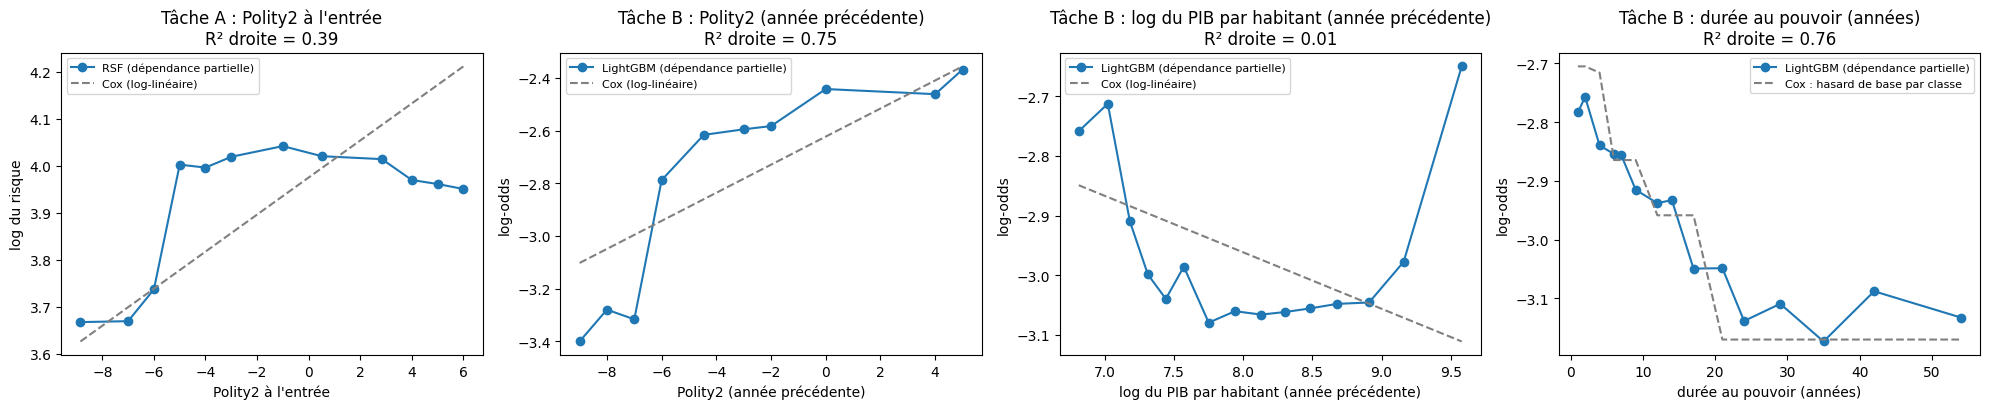

,tâche,modèle,variable,R² droite,pente de la droite,forme
0,A,RSF,polity2_entry,0.387,0.018,croissante avec un seuil entre -6 et -5
1,B,LightGBM,polity2_lag1,0.746,0.070,croissante avec un seuil entre -7 et -6
2,B,LightGBM,log_gdppc_lag1,0.010,-0.017,en U (minimum vers 7.75)
3,B,LightGBM,start,0.760,-0.008,décroissante avec un plateau


In [23]:
# ============================================================
# 6.2 Dépendance partielle et linéarité
# ============================================================
R2_LINEAR = 0.9
N_GRID = 15


def grid_for(values, integer=False):
    q = np.percentile(values, np.linspace(5, 95, N_GRID))
    return np.unique(q.round()) if integer else np.unique(q.round(2))


def describe_shape(x, y):
    """Forme d'une courbe non linéaire, selon les règles annoncées dans le markdown."""
    amplitude = y.max() - y.min()
    i_min, i_max = int(np.argmin(y)), int(np.argmax(y))
    interior = lambda i: 0 < i < len(y) - 1
    if interior(i_min) and min(y[0], y[-1]) - y[i_min] >= amplitude / 4:
        return f"en U (minimum vers {x[i_min]:g})"
    if interior(i_max) and y[i_max] - max(y[0], y[-1]) >= amplitude / 4:
        return f"en cloche (maximum vers {x[i_max]:g})"
    direction = "croissante" if y[-1] > y[0] else "décroissante"
    steps = np.abs(np.diff(y))
    j = int(np.argmax(steps))
    if steps[j] > 0.5 * abs(y[-1] - y[0]):
        return f"{direction} avec un seuil entre {x[j]:g} et {x[j + 1]:g}"
    return f"{direction} avec un plateau"


pd_specs = [
    ("A", "RSF", "polity2_entry", "Polity2 à l'entrée", False),
    ("B", "LightGBM", "polity2_lag1", "Polity2 (année précédente)", False),
    ("B", "LightGBM", "log_gdppc_lag1", "log du PIB par habitant (année précédente)", False),
    ("B", "LightGBM", "start", "durée au pouvoir (années)", True),
]
linearity_rows, curves = [], {}
fig, axes = plt.subplots(1, len(pd_specs), figsize=(5 * len(pd_specs), 4.2))
for ax, (task, model, var, label, integer) in zip(axes, pd_specs):
    data = static if task == "A" else tv
    grid = grid_for(data[var], integer)
    per_fold, cox_slopes, baselines = [], [], []
    for info in (interp_A if task == "A" else interp_B):
        X = info["test"].copy()
        values = []
        for v in grid:
            X[var] = v
            if task == "A":
                values.append(np.mean(np.log(info["rsf"].predict(X[info["features"]]))))
            else:
                values.append(np.mean(info["lgbm"].predict(X[info["features"] + ["start"]], raw_score=True)))
        per_fold.append(values)
        if var != "start":
            model_cox = info["cox"] if task == "A" else info["ctv"]
            cox_slopes.append(model_cox.params_[var])
        else:
            codes = pd.cut(grid, TIME_BINS, labels=False)
            baselines.append(np.log(info["h0_bins"].reindex(codes).values))
    y = np.mean(per_fold, axis=0)
    slope, intercept = np.polyfit(grid, y, 1)
    r2 = 1 - ((y - (slope * grid + intercept)) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    if var != "start":
        cox_curve = y.mean() + np.mean(cox_slopes) * (grid - grid.mean())
        cox_label = "Cox (log-linéaire)"
    else:
        b = np.mean(baselines, axis=0)
        cox_curve = y.mean() + (b - b.mean())
        cox_label = "Cox : hasard de base par classe"
    curves[var] = (grid, y)
    ax.plot(grid, y, marker="o", label=f"{model} (dépendance partielle)")
    ax.plot(grid, cox_curve, linestyle="--", color="grey", label=cox_label)
    ax.set_title(f"Tâche {task} : {label}\nR² droite = {r2:.2f}")
    ax.set_xlabel(label)
    ax.set_ylabel("log du risque" if task == "A" else "log-odds")
    ax.legend(fontsize=8)
    linearity_rows.append({"tâche": task, "modèle": model, "variable": var, "R² droite": r2,
                           "pente de la droite": slope,
                           "forme": "proche de linéaire" if r2 >= R2_LINEAR else describe_shape(grid, y)})
plt.tight_layout()
plt.show()
linearity = pd.DataFrame(linearity_rows)
display(linearity.round(3))


### 6.3 Valeurs SHAP (Tâche B, LightGBM)

Les valeurs SHAP décomposent chaque prédiction de LightGBM (en log-odds) en contributions des variables : une valeur positive pousse vers un risque de chute plus élevé. Elles sont calculées hors échantillon, pli par pli, avec `TreeExplainer`.

**Critère de direction, fixé avant les résultats :** pour chaque covariable, on calcule la corrélation de Spearman entre sa valeur et sa valeur SHAP. L'effet appris par LightGBM est dit **de même sens que le modèle de Cox time-varying** si le signe de cette corrélation est celui du log hazard ratio de `final_panel.ipynb` et si la corrélation est significative au seuil $\alpha$. La durée au pouvoir n'a pas de coefficient dans le modèle de Cox et n'entre pas dans cette comparaison.

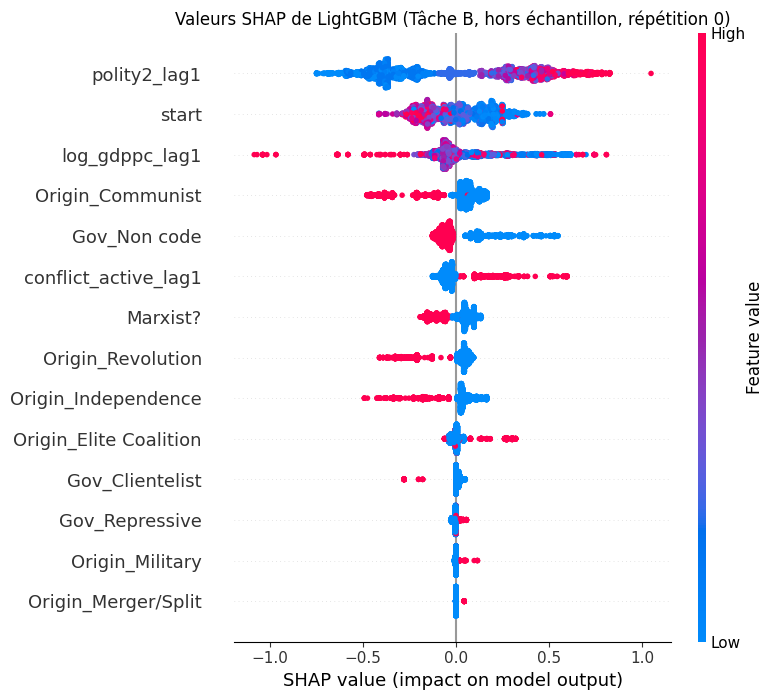

,"Spearman (valeur, SHAP)",p,log HR Cox time-varying,p Cox,même sens,importance SHAP (moyenne |SHAP|)
covariable,,,,,,
polity2_lag1,0.8707,0.0,0.0526,0.000,True,0.3744
log_gdppc_lag1,-0.3156,0.0,-0.1031,0.212,True,0.1340
Origin_Communist,-0.6915,0.0,-0.5870,0.022,True,0.1179
Gov_Non code,-0.7792,0.0,-0.4479,0.020,True,0.0959
conflict_active_lag1,0.6798,0.0,0.3688,0.017,True,0.0791
Marxist?,-0.8226,0.0,-0.2771,0.120,True,0.0763
Origin_Revolution,-0.6005,0.0,-0.5293,0.013,True,0.0755
Origin_Independence,-0.6492,0.0,-0.4813,0.024,True,0.0753
Origin_Elite Coalition,0.2559,0.0,-0.1370,0.479,False,0.0244


**Question 3 : les effets appris par LightGBM vont-ils dans le même sens que ceux du modèle de Cox ?**

- Pour le conflit armé de l'année précédente, LightGBM augmente le risque quand la valeur augmente (Spearman = 0.68, p < 0,001) ; le modèle de Cox augmente le risque (HR = 1.45, p = 0.017) → **même sens**.
- Pour le score Polity2 de l'année précédente, LightGBM augmente le risque quand la valeur augmente (Spearman = 0.87, p < 0,001) ; le modèle de Cox augmente le risque (HR = 1.05, p = 0.000) → **même sens**.

Parmi les 6 covariables significatives dans le modèle de Cox time-varying, 6 ont un effet de même sens dans LightGBM selon le critère annoncé (`polity2_lag1`, `Origin_Communist`, `conflict_active_lag1`, `Origin_Revolution`, `Origin_Independence`, `Gov_Clientelist`). La modalité `Gov_Non code`, qui n'est pas une stratégie mais une absence de codage, est exclue de ce décompte.

In [24]:
# ============================================================
# 6.3 Valeurs SHAP de LightGBM (hors échantillon) et direction des effets
# ============================================================
shap_values, shap_inputs = [], []
for info in interp_B:
    X = info["test"][info["features"] + ["start"]]
    with warnings.catch_warnings():   # avertissement de shap sur le format de sortie (sans effet ici)
        warnings.simplefilter("ignore", UserWarning)
        values = shap.TreeExplainer(info["lgbm"]).shap_values(X)
    values = values[1] if isinstance(values, list) else values
    shap_values.append(pd.DataFrame(values, columns=X.columns))
    shap_inputs.append(X.reset_index(drop=True))
shap_values = pd.concat(shap_values, ignore_index=True)[TV_FEATURES + ["start"]]
shap_inputs = pd.concat(shap_inputs, ignore_index=True)[TV_FEATURES + ["start"]]

shap.summary_plot(shap_values.values, shap_inputs, show=False)
plt.title("Valeurs SHAP de LightGBM (Tâche B, hors échantillon, répétition 0)")
plt.tight_layout()
plt.show()

log_hr_tv = np.log(table_53["HR time-varying"].dropna())
p_tv = table_53["p time-varying"].dropna()
direction_rows = []
for var in TV_FEATURES:
    rho, p = stats.spearmanr(shap_inputs[var], shap_values[var])
    same = bool(np.sign(rho) == np.sign(log_hr_tv[var]) and p < ALPHA)
    direction_rows.append({"covariable": var, "Spearman (valeur, SHAP)": rho, "p": p,
                           "log HR Cox time-varying": log_hr_tv[var], "p Cox": p_tv[var],
                           "même sens": same,
                           "importance SHAP (moyenne |SHAP|)": shap_values[var].abs().mean()})
shap_direction = pd.DataFrame(direction_rows).set_index("covariable").sort_values(
    "importance SHAP (moyenne |SHAP|)", ascending=False)
display(shap_direction.round(4))

key_vars = {"conflict_active_lag1": "le conflit armé de l'année précédente", "polity2_lag1": "le score Polity2 de l'année précédente"}
def fmt_p(p):
    return "p < 0,001" if p < 0.001 else f"p = {p:.3f}"


NOT_CODED_TV = "Gov_Non code"   # modalité « non codé » : pas une stratégie, exclue des effets substantiels
key_lines = []
for var, name in key_vars.items():
    r = shap_direction.loc[var]
    sens_shap = "augmente" if r["Spearman (valeur, SHAP)"] > 0 else "réduit"
    sens_cox = "augmente" if r["log HR Cox time-varying"] > 0 else "réduit"
    key_lines.append(f"- Pour {name}, LightGBM {sens_shap} le risque quand la valeur augmente (Spearman = "
                     f"{r['Spearman (valeur, SHAP)']:.2f}, {fmt_p(r['p'])}) ; le modèle de Cox {sens_cox} le risque "
                     f"(HR = {np.exp(r['log HR Cox time-varying']):.2f}, p = {r['p Cox']:.3f}) → "
                     f"**{'même sens' if r['même sens'] else 'pas de concordance établie'}**.")
cox_sig_tv = shap_direction[(shap_direction["p Cox"] < ALPHA) & (shap_direction.index != NOT_CODED_TV)]
display(Markdown(
    "**Question 3 : les effets appris par LightGBM vont-ils dans le même sens que ceux du modèle de Cox ?**\n\n"
    + "\n".join(key_lines) + "\n\n"
    f"Parmi les {len(cox_sig_tv)} covariables significatives dans le modèle de Cox time-varying, "
    f"{int(cox_sig_tv['même sens'].sum())} ont un effet de même sens dans LightGBM selon le critère annoncé "
    f"({', '.join(f'`{v}`' for v in cox_sig_tv.index[cox_sig_tv['même sens']]) or 'aucune'}). "
    f"La modalité `{NOT_CODED_TV}`, qui n'est pas une stratégie mais une absence de codage, est exclue de ce décompte."
))


## 7. Limites et conclusion

In [25]:
# ============================================================
# 7. Limites et conclusion (générées à partir des résultats)
# ============================================================
# Question 2 : linéarité
lin_lines = [f"- {r['variable']} (Tâche {r['tâche']}, {r['modèle']}) : R² de la droite = {r['R² droite']:.2f} → {r['forme']}."
             for _, r in linearity.iterrows()]
covariate_lin = linearity[linearity["variable"] != "start"]
n_nonlinear = int((covariate_lin["R² droite"] < R2_LINEAR).sum())

ml_won = any(v["better"] for t in TASKS.values() for v in t["verdicts"].values())
spec_note = ("Ces écarts n'améliorent toutefois pas la prédiction (question 1) : les modèles qui peuvent les capter ne "
             "font pas mieux que le modèle de Cox, ce qui suggère qu'ils sont faibles ou mal estimés avec ce nombre "
             "de chutes." if not ml_won else
             "Au moins un modèle capable de capter ces écarts prédit mieux que le modèle de Cox (question 1) : ils "
             "méritent d'être modélisés explicitement.")

# Question 3 : cohérence
n_consistent = int(consistency["cohérent"].sum())
consistency_lines = [f"- Tâche {r['tâche']}, {r['modèle']} : {r['significatifs dans le top k']} des "
                     f"{r['significatifs dans Cox']} facteurs significatifs dans Cox figurent parmi les {r['k']} premiers"
                     f"{'' if r['cohérent'] else ' (hors du top : ' + r['hors du top k'] + ')'} → "
                     f"**{'cohérent' if r['cohérent'] else 'pas entièrement cohérent'}**."
                     for _, r in consistency.iterrows()]

# Limites (chiffres calculés)
n_spells_A = len(static)
pct_marxist_communist = static.loc[static["Origin_Communist"] == 1, "Marxist?"].mean() * 100
first_bin = pd.crosstab(initial_bins, tv["event"]).loc["0"]
step_zero_share = step_diagnostics["share_zero"].mean() * 100

if not any(v["better"] for t in TASKS.values() for v in t["verdicts"].values()):
    practical = ("**Conclusion pratique.** Les modèles d'apprentissage automatique ne prédisent pas mieux que les "
                 "modèles de Cox, dans aucun des deux cadres. Nous conservons donc les modèles de Cox de "
                 "`final_panel.ipynb` pour le rapport (inférence : hazard ratios, intervalles de confiance, tests) et "
                 "le modèle de Cox statique corrigé (Section 6.3 de `final_panel.ipynb`) pour l'application web : à "
                 "performance égale, il est interprétable et ses prédictions s'expliquent par des effets estimés et "
                 "testés.")
else:
    practical = ("**Conclusion pratique.** Au moins un modèle d'apprentissage automatique prédit mieux que le modèle de "
                 "Cox selon les règles fixées : le choix du modèle de l'application web doit être réexaminé.")

display(Markdown(
    "### 7.1 Réponses aux questions\n\n"
    "**1. Prédiction.** " + q1_text + "\n\n"
    "**2. Spécification.** La dépendance partielle des modèles flexibles indique que "
    f"{n_nonlinear} des {len(covariate_lin)} effets de covariables examinés s'écartent d'une forme linéaire selon le "
    f"critère annoncé ($R^2$ < {R2_LINEAR}) :\n\n" + "\n".join(lin_lines) + "\n\n"
    + spec_note + "\n\n"
    "**3. Cohérence.** " + f"{n_consistent} des {len(consistency)} classements par permutation sont cohérents avec les "
    "facteurs significatifs des modèles de Cox, selon le critère annoncé en 6.1 :\n\n" + "\n".join(consistency_lines) + "\n\n"
    + "\n".join(key_lines) + "\n\n" + practical
))

display(Markdown(
    "### 7.2 Limites\n\n"
    f"* **Petits effectifs (Tâche A)** : {n_spells_A} spells, dont {censored_total} censurés seulement (au moins "
    f"{censored_min} par pli de test). Le C-index d'Uno et le score de Brier, fondés sur la censure, sont bruités : "
    + " ; ".join(noise_lines) + ".\n"
    f"* **Événement rare (Tâche B)** : les chutes représentent {event_rate_tv:.1f} % des parti-années, et le jeu "
    f"time-varying ne conserve que {n_events_tv} des {n_ended_spells} chutes du panel (données macro manquantes).\n"
    f"* **Interprétation sur une seule répétition** : les importances, dépendances partielles et valeurs SHAP "
    f"proviennent des {N_FOLDS} plis de la répétition {INTERP_REP} ; elles décrivent les modèles, sans test de "
    "stabilité d'une répétition à l'autre.\n"
    f"* **Covariables corrélées** : {pct_marxist_communist:.0f} % des partis d'origine communiste sont aussi codés "
    "marxistes-léninistes ; quand deux variables portent la même information, l'importance par permutation se partage "
    "entre elles et chacune peut paraître moins importante qu'elle ne l'est.\n"
    f"* **Deux choix documentés en Section 4** : le modèle de Cox time-varying est évalué avec un hasard de base "
    f"constant par classe de durée, car l'estimateur de Breslow en escalier attribue une probabilité nulle à "
    f"{step_zero_share:.1f} % des parti-années de test ; la première année au pouvoir ({int(first_bin.sum())} "
    f"parti-années, {int(first_bin.get(1, 0))} chute) est fusionnée avec la classe 1-2 ans.\n"
    "* **Critère de cohérence (6.1) ajusté** : lorsque plus de la moitié des facteurs sont significatifs dans le "
    "modèle de Cox, le seuil « moitié supérieure du classement » est remplacé par le nombre de facteurs "
    "significatifs, faute de quoi le critère serait impossible à satisfaire."
))


### 7.1 Réponses aux questions

**1. Prédiction.** Dans les deux cadres, aucun des 4 modèles comparés au modèle de Cox (RSF (Tâche A), GBSA (Tâche A), Logistique (Tâche B), LightGBM (Tâche B)) ne prédit mieux que lui selon les règles fixées en 3.4 et 4.4 : **les modèles de Cox ne sont pas surpassés**, que la survie soit prédite à partir de la situation à l'entrée au pouvoir ou année par année.

**2. Spécification.** La dépendance partielle des modèles flexibles indique que 3 des 3 effets de covariables examinés s'écartent d'une forme linéaire selon le critère annoncé ($R^2$ < 0.9) :

- polity2_entry (Tâche A, RSF) : R² de la droite = 0.39 → croissante avec un seuil entre -6 et -5.
- polity2_lag1 (Tâche B, LightGBM) : R² de la droite = 0.75 → croissante avec un seuil entre -7 et -6.
- log_gdppc_lag1 (Tâche B, LightGBM) : R² de la droite = 0.01 → en U (minimum vers 7.75).
- start (Tâche B, LightGBM) : R² de la droite = 0.76 → décroissante avec un plateau.

Ces écarts n'améliorent toutefois pas la prédiction (question 1) : les modèles qui peuvent les capter ne font pas mieux que le modèle de Cox, ce qui suggère qu'ils sont faibles ou mal estimés avec ce nombre de chutes.

**3. Cohérence.** 3 des 5 classements par permutation sont cohérents avec les facteurs significatifs des modèles de Cox, selon le critère annoncé en 6.1 :

- Tâche A, Cox : 3 des 3 facteurs significatifs dans Cox figurent parmi les 3 premiers → **cohérent**.
- Tâche A, RSF : 2 des 3 facteurs significatifs dans Cox figurent parmi les 3 premiers (hors du top : Gouvernance) → **pas entièrement cohérent**.
- Tâche A, GBSA : 2 des 3 facteurs significatifs dans Cox figurent parmi les 3 premiers (hors du top : Gouvernance) → **pas entièrement cohérent**.
- Tâche B, Cox time-varying : 4 des 4 facteurs significatifs dans Cox figurent parmi les 4 premiers → **cohérent**.
- Tâche B, LightGBM : 4 des 4 facteurs significatifs dans Cox figurent parmi les 4 premiers → **cohérent**.

- Pour le conflit armé de l'année précédente, LightGBM augmente le risque quand la valeur augmente (Spearman = 0.68, p < 0,001) ; le modèle de Cox augmente le risque (HR = 1.45, p = 0.017) → **même sens**.
- Pour le score Polity2 de l'année précédente, LightGBM augmente le risque quand la valeur augmente (Spearman = 0.87, p < 0,001) ; le modèle de Cox augmente le risque (HR = 1.05, p = 0.000) → **même sens**.

**Conclusion pratique.** Les modèles d'apprentissage automatique ne prédisent pas mieux que les modèles de Cox, dans aucun des deux cadres. Nous conservons donc les modèles de Cox de `final_panel.ipynb` pour le rapport (inférence : hazard ratios, intervalles de confiance, tests) et le modèle de Cox statique corrigé (Section 6.3 de `final_panel.ipynb`) pour l'application web : à performance égale, il est interprétable et ses prédictions s'expliquent par des effets estimés et testés.

### 7.2 Limites

* **Petits effectifs (Tâche A)** : 224 spells, dont 29 censurés seulement (au moins 5 par pli de test). Le C-index d'Uno et le score de Brier, fondés sur la censure, sont bruités : pour le C-index d'Uno, la dispersion entre plis (écart-type moyen 0.040) est plus grande que le plus grand écart moyen avec le modèle de Cox (0.009) ; pour le score de Brier intégré, la dispersion entre plis (écart-type moyen 0.026) est plus grande que le plus grand écart moyen avec le modèle de Cox (0.003).
* **Événement rare (Tâche B)** : les chutes représentent 5.3 % des parti-années, et le jeu time-varying ne conserve que 194 des 247 chutes du panel (données macro manquantes).
* **Interprétation sur une seule répétition** : les importances, dépendances partielles et valeurs SHAP proviennent des 5 plis de la répétition 0 ; elles décrivent les modèles, sans test de stabilité d'une répétition à l'autre.
* **Covariables corrélées** : 100 % des partis d'origine communiste sont aussi codés marxistes-léninistes ; quand deux variables portent la même information, l'importance par permutation se partage entre elles et chacune peut paraître moins importante qu'elle ne l'est.
* **Deux choix documentés en Section 4** : le modèle de Cox time-varying est évalué avec un hasard de base constant par classe de durée, car l'estimateur de Breslow en escalier attribue une probabilité nulle à 16.7 % des parti-années de test ; la première année au pouvoir (50 parti-années, 1 chute) est fusionnée avec la classe 1-2 ans.
* **Critère de cohérence (6.1) ajusté** : lorsque plus de la moitié des facteurs sont significatifs dans le modèle de Cox, le seuil « moitié supérieure du classement » est remplacé par le nombre de facteurs significatifs, faute de quoi le critère serait impossible à satisfaire.

### 7.3 Références (méthodes)

- **Breiman, L.** (2001). Random Forests. *Machine Learning*, 45(1), 5–32. https://doi.org/10.1023/A:1010933404324 — forêts aléatoires et importance par permutation.
- **Ishwaran, H., Kogalur, U. B., Blackstone, E. H., & Lauer, M. S.** (2008). Random survival forests. *The Annals of Applied Statistics*, 2(3). https://doi.org/10.1214/08-AOAS169
- **Friedman, J. H.** (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics*, 29(5). https://doi.org/10.1214/aos/1013203451 — gradient boosting et dépendance partielle.
- **Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y.** (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree.
- **Pölsterl, S.** (2020). scikit-survival: A Library for Time-to-Event Analysis Built on Top of scikit-learn.
- **Lundberg, S. M., & Lee, S.-I.** (2017). A Unified Approach to Interpreting Model Predictions.
- **Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., et al.** (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- **Nadeau, C., & Bengio, Y.** (2003). Inference for the Generalization Error. *Machine Learning*, 52(3), 239–281. https://doi.org/10.1023/A:1024068626366
- **Bouckaert, R. R., & Frank, E.** (2004). Evaluating the Replicability of Significance Tests for Comparing Learning Algorithms. In *Advances in Knowledge Discovery and Data Mining* (Lecture Notes in Computer Science), 3–12. https://doi.org/10.1007/978-3-540-24775-3_3
- **Harrell, F. E., Califf, R. M., Pryor, D. B., Lee, K. L., & Rosati, R. A.** (1982). Evaluating the Yield of Medical Tests. *JAMA*, 247(18). https://doi.org/10.1001/jama.1982.03320430047030
- **Uno, H., Cai, T., Pencina, M. J., D'Agostino, R. B., & Wei, L. J.** (2011). On the C-statistics for evaluating overall adequacy of risk prediction procedures with censored survival data. *Statistics in Medicine*, 30(10), 1105–1117. https://doi.org/10.1002/sim.4154
- **Graf, E., Schmoor, C., Sauerbrei, W., & Schumacher, M.** (1999). Assessment and comparison of prognostic classification schemes for survival data. *Statistics in Medicine*, 18(17–18), 2529–2545. https://doi.org/10.1002/(SICI)1097-0258(19990915/30)18:17/18<2529::AID-SIM274>3.0.CO;2-5

Les références sans revue ni DOI (Ke et al., 2017 ; Pölsterl, 2020 ; Lundberg & Lee, 2017) n'ont pas pu être vérifiées dans Crossref et sont données par auteurs, année et titre seulement.

## 8. Export des résultats pour le site

Les résultats des sections 3 à 7 (scores par modèle, tests appariés, importance par permutation, linéarité, directions SHAP, réponses aux questions) sont écrits dans `data/processed/site_results_ml.json`, lu par `frontend/build_data.py` pour la page « Analyse » du site. Les textes générés sont réécrits en français, en anglais et en arabe par `src/site_text.py`, à partir des mêmes chiffres.

In [26]:
# ============================================================
# 8. Export des résultats pour le site
# ============================================================
import sys

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from site_export import write_json
from site_text import ml_texts


def metric_summary(res, models, metrics):
    out = []
    for m in models:
        d = res[res["model"] == m]
        row = {"model": m}
        for metric in metrics:
            s = d[metric].dropna()
            row[metric] = {"mean": float(s.mean()), "sd": float(s.std())} if len(s) else None
        out.append(row)
    return out


site_ml = {
    "source": "notebooks/03_ml_survival.ipynb",
    "protocol": {"folds": N_FOLDS, "repeats": N_REPEATS, "evaluations": N_FOLDS * N_REPEATS,
                 "grouped_by": "Country", "interpretation_repetition": INTERP_REP,
                 "test": "test t rééchantillonné corrigé (Nadeau & Bengio, 2003)"},
    "task_a": {
        "label": "Tâche A : survie par spell", "spells": len(static), "events": int(static["event"].sum()),
        "censored": censored_total, "censored_min_per_fold": censored_min,
        "metrics": metric_summary(results, MODELS, ["harrell_c", "uno_c", "ibs"] + [f"auc_{t}" for t in AUC_TIMES]),
        "tests": tests,
        "verdicts": {m: {"better": v["better"], "worse": v["worse_c"]} for m, v in verdicts.items()},
    },
    "task_b": {
        "label": "Tâche B : hasard annuel (temps discret)", "rows": len(tv), "spells": int(tv["spell_id"].nunique()),
        "events": n_events_tv, "event_rate": float(event_rate_tv), "events_in_panel": n_ended_spells,
        "metrics": metric_summary(results_B, MODELS_B, ["roc_auc", "pr_auc", "brier", "log_loss", "mean_predicted"]),
        "tests": tests_B,
        "verdicts": {m: {"better": v["better"], "worse": v["worse"]} for m, v in verdicts_B.items()},
        "calibration_rep0": calibration_B,
    },
    "comparison": summary_both.reset_index(),
    "interpretation": {
        "permutation": [{"task": t, "model": m, "ranking": tab.reset_index()} for (t, m), tab in ranking_tables.items()],
        "consistency": consistency,
        "linearity": linearity,
        "partial_dependence": {var: {"x": list(map(float, g)), "y": list(map(float, y))} for var, (g, y) in curves.items()},
        "shap_direction": shap_direction.reset_index(),
    },
}
# Réponses et limites des sections 5 à 7, en français, anglais et arabe, à partir des mêmes chiffres
site_ml["texts"] = ml_texts(site_ml)
size_kb = write_json(PROJECT_ROOT / "data" / "processed" / "site_results_ml.json", site_ml)
print(f"data/processed/site_results_ml.json : {size_kb:.0f} Ko")


data/processed/site_results_ml.json : 30 Ko
